C:\Users\VEDANT\AppData\Local\Temp\ipykernel_18036\2379709503.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)["Close"]


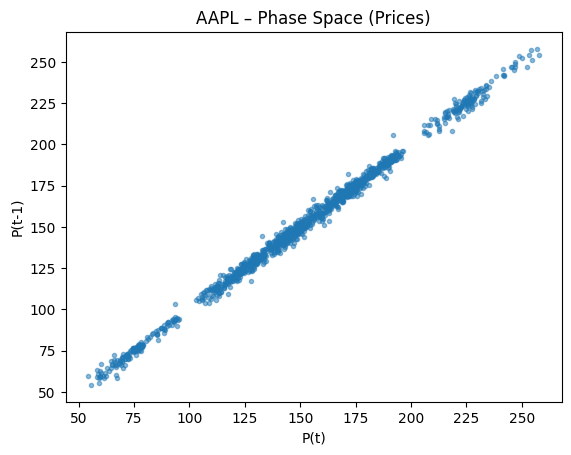

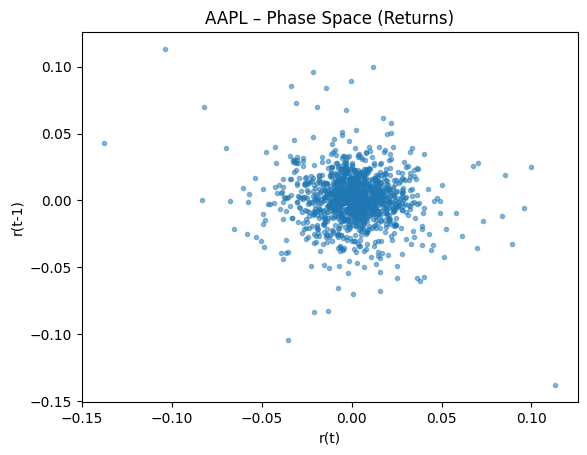

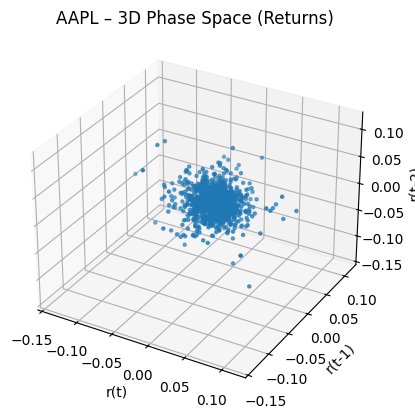

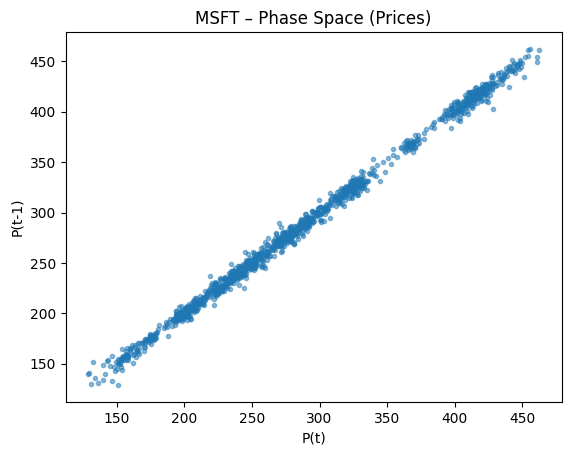

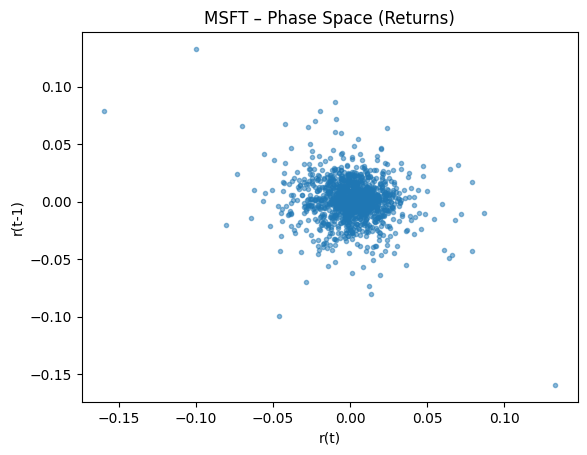

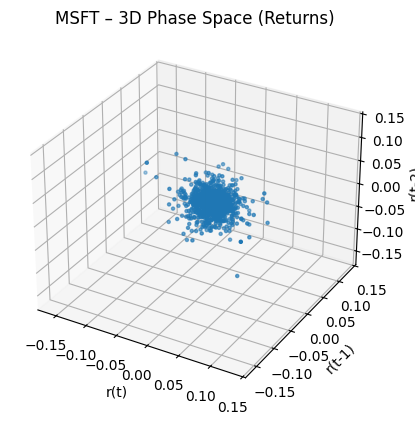

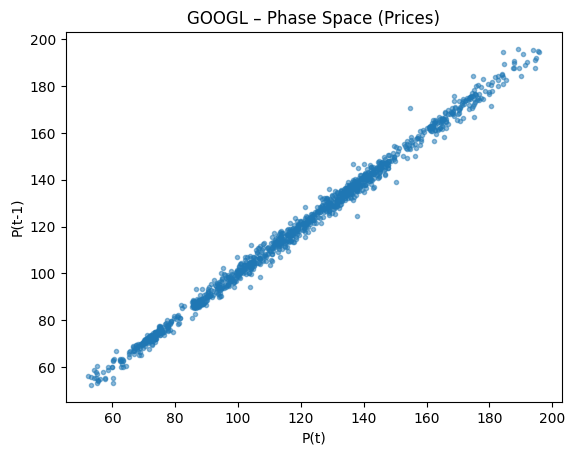

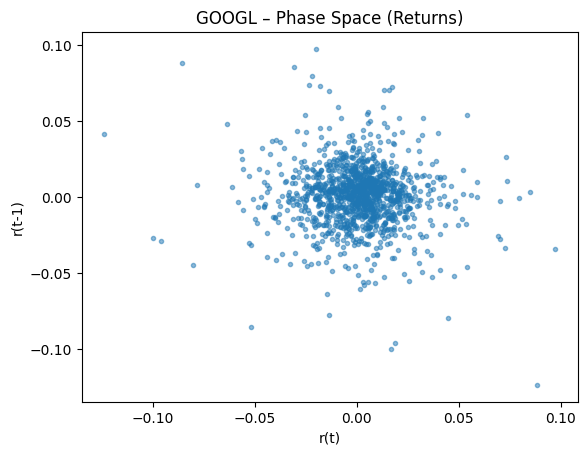

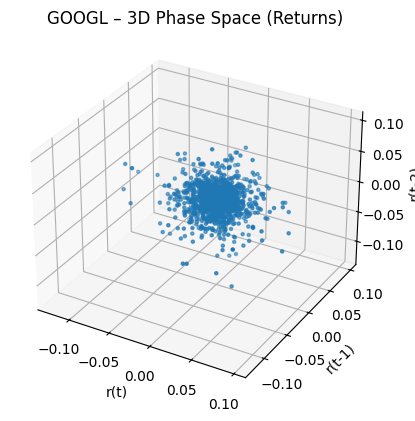

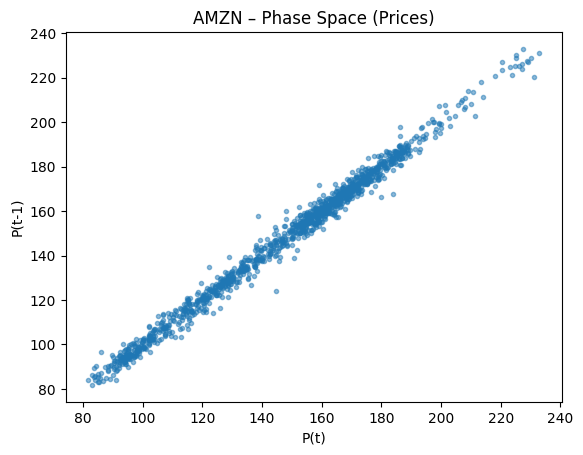

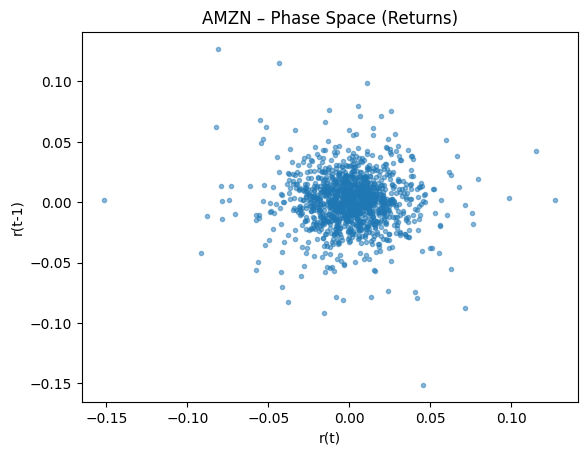

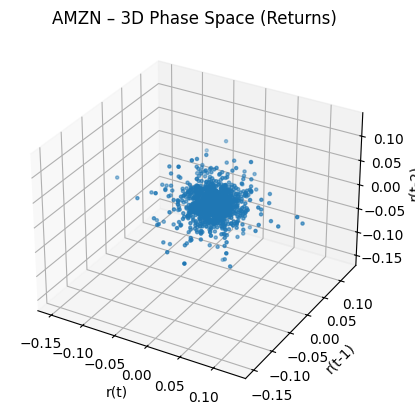

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# --------------------------------
# 1. Configuration
# --------------------------------
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN"]
start_date = "2020-01-01"
end_date = "2025-01-01"
embedding_dim = 3
max_lag = 50

# --------------------------------
# 2. Helper functions
# --------------------------------
def choose_tau(series, max_lag=50):
    acf_vals = acf(series, nlags=max_lag, fft=True)
    for i in range(1, len(acf_vals)):
        if acf_vals[i] < 1 / np.e:
            return i
    return 1

def takens_embedding(series, m, tau):
    n = len(series)
    embedded = np.empty((n - (m - 1) * tau, m))
    for i in range(m):
        embedded[:, i] = series[i * tau : n - (m - 1) * tau + i * tau]
    return embedded

# --------------------------------
# 3. Download data
# --------------------------------
data = yf.download(tickers, start=start_date, end=end_date, progress=False)["Close"]

# --------------------------------
# 4. Loop over stocks
# --------------------------------
for ticker in tickers:
    prices = data[ticker].dropna()
    returns = np.log(prices).diff().dropna()

    # choose delays
    tau_price = choose_tau(prices.values, max_lag)
    tau_return = choose_tau(returns.values, max_lag)

    # embeddings
    X_price = takens_embedding(prices.values, embedding_dim, tau_price)
    X_return = takens_embedding(returns.values, embedding_dim, tau_return)

    # --------------------------------
    # 5. Plot price phase space (2D)
    # --------------------------------
    plt.figure()
    plt.plot(X_price[:, 0], X_price[:, 1], ".", alpha=0.5)
    plt.xlabel("P(t)")
    plt.ylabel(f"P(t-{tau_price})")
    plt.title(f"{ticker} – Phase Space (Prices)")
    plt.show()

    # --------------------------------
    # 6. Plot return phase space (2D)
    # --------------------------------
    plt.figure()
    plt.plot(X_return[:, 0], X_return[:, 1], ".", alpha=0.5)
    plt.xlabel("r(t)")
    plt.ylabel(f"r(t-{tau_return})")
    plt.title(f"{ticker} – Phase Space (Returns)")
    plt.show()

    # --------------------------------
    # 7. Plot return phase space (3D)
    # --------------------------------
    fig = plt.figure()
    ax = fig.add_subplot(projection="3d")
    ax.scatter(
        X_return[:, 0],
        X_return[:, 1],
        X_return[:, 2],
        s=5
    )
    ax.set_xlabel("r(t)")
    ax.set_ylabel(f"r(t-{tau_return})")
    ax.set_zlabel(f"r(t-{2 * tau_return})")
    ax.set_title(f"{ticker} – 3D Phase Space (Returns)")
    plt.show()



Processing AAPL...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 31, Selected: 18
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


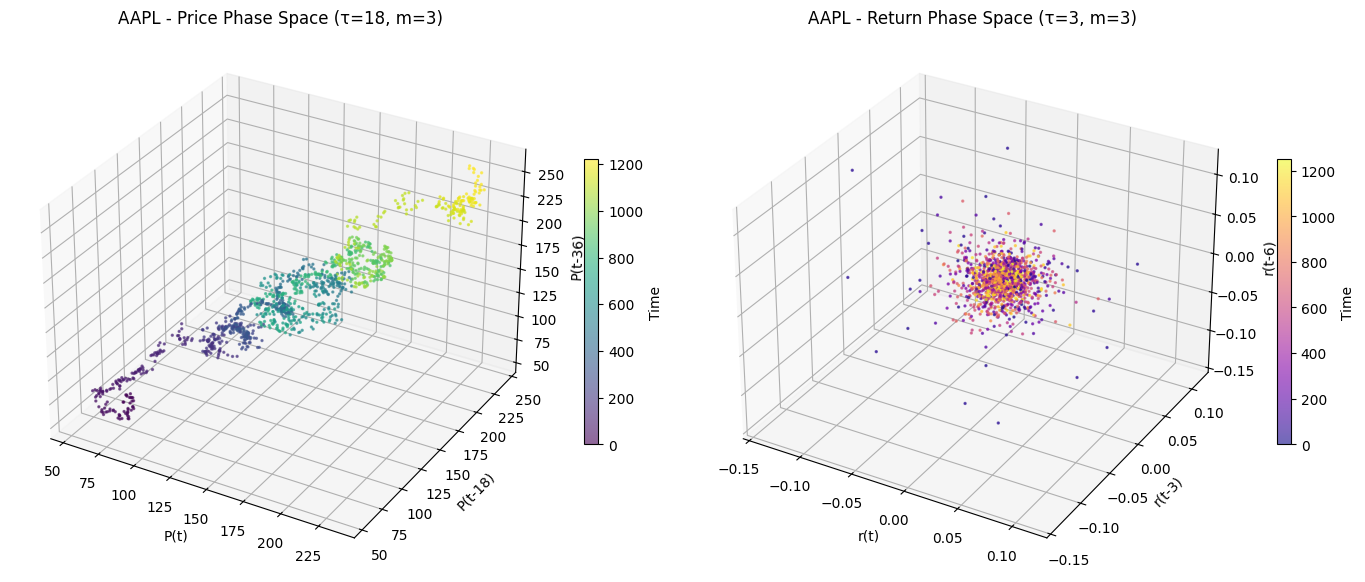


Processing MSFT...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 25, Selected: 15
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


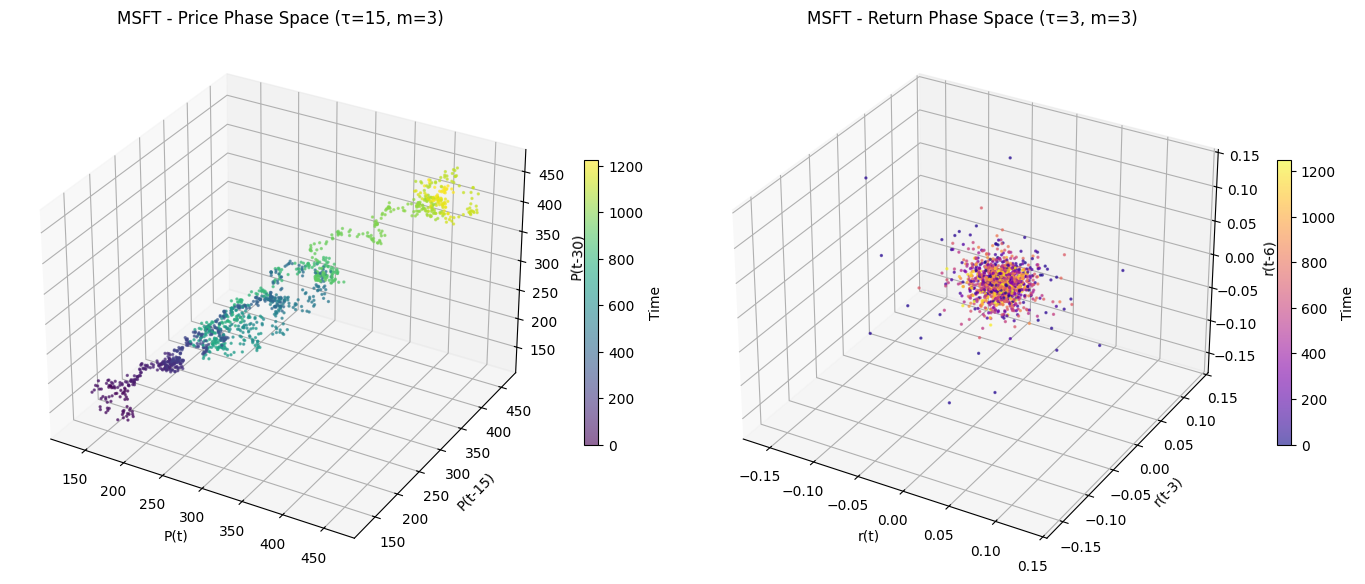


Processing GOOGL...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 21, Selected: 13
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


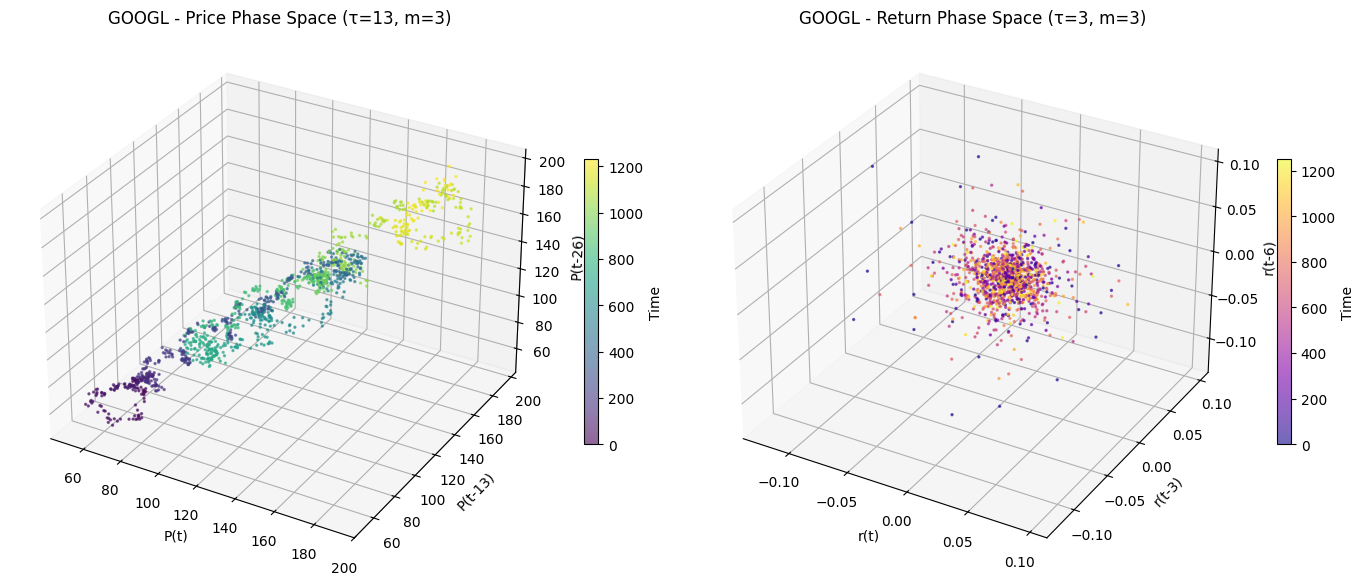


Processing TSLA...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 25, Selected: 15
  Return tau - ACF: 3, MI: 2, Selected: 2
  Embedding dimensions - Prices: 3, Returns: 3


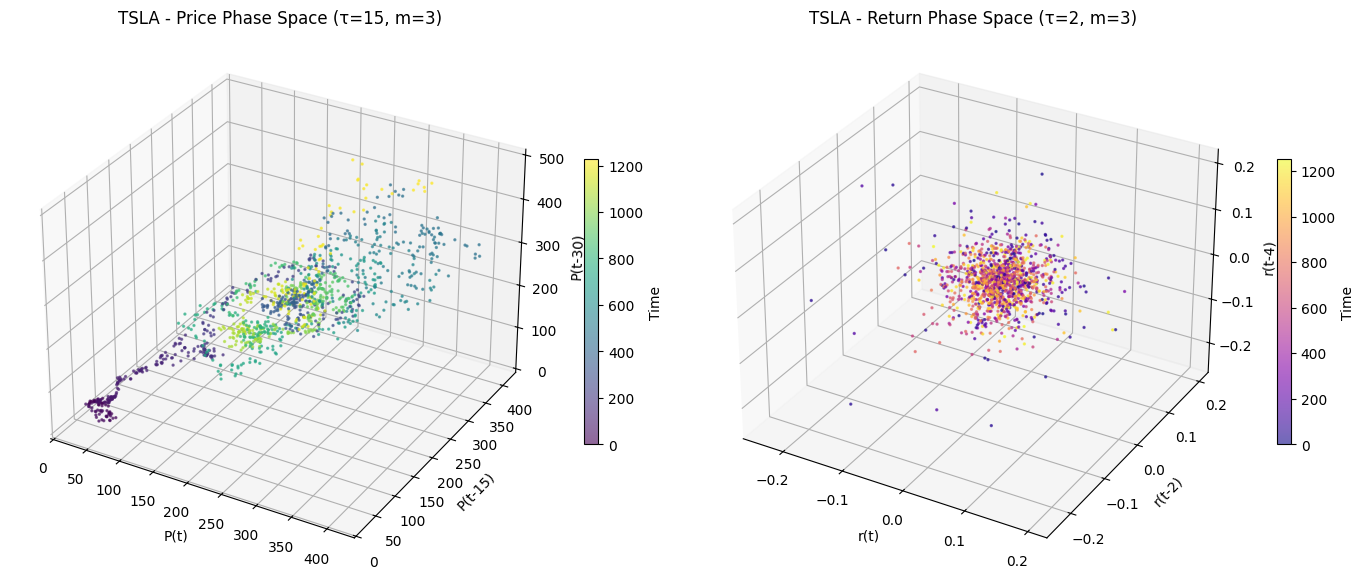


Processing AMZN...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 16, Selected: 10
  Return tau - ACF: 3, MI: 4, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


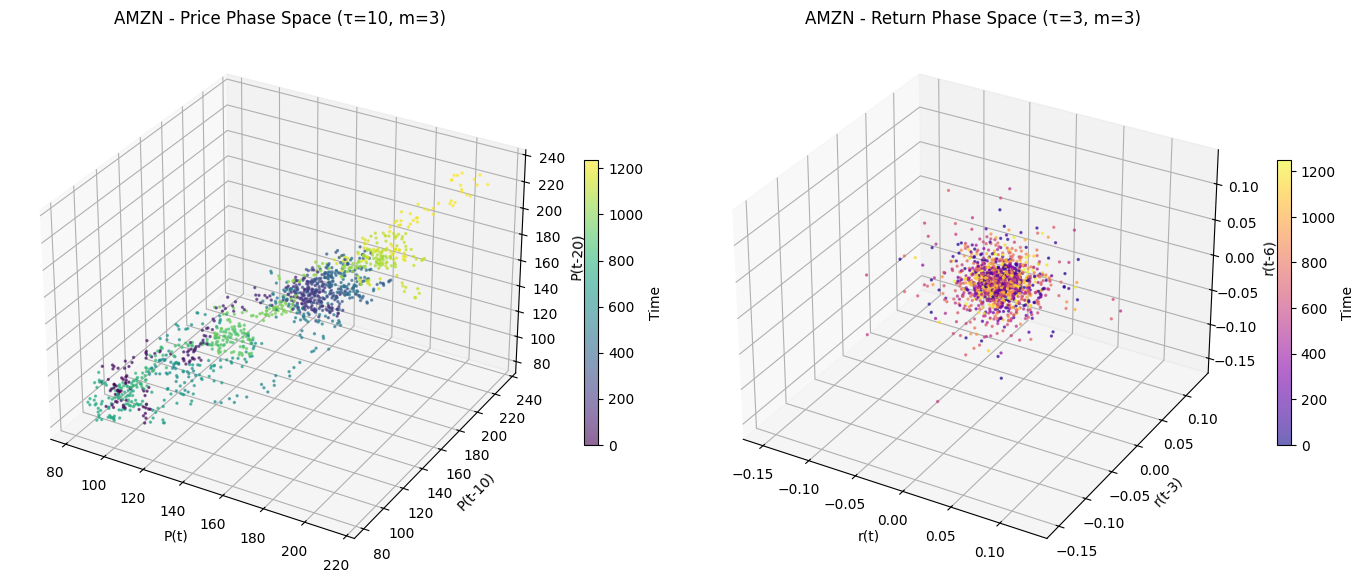


Processing complete!


In [2]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from statsmodels.tsa.stattools import acf

tickers = ["AAPL", "MSFT", "GOOGL", "TSLA", "AMZN"]
start = "2020-01-01"
end = "2025-01-01"
m = 3
max_lag = 50

def mutual_information_delay(series, max_lag=50):
    series = np.array(series).flatten()
    series = (series - np.mean(series)) / np.std(series)
    n_bins = max(10, int(np.sqrt(len(series) / 5)))
    
    def mi(x, y, bins):
        hist_2d, _, _ = np.histogram2d(x, y, bins=bins)
        pxy = hist_2d / (np.sum(hist_2d) + 1e-10)
        px = np.sum(pxy, axis=1)
        py = np.sum(pxy, axis=0)
        px_py = px[:, None] * py[None, :] + 1e-10
        nzs = pxy > 0
        return np.sum(pxy[nzs] * np.log(pxy[nzs] / px_py[nzs]))
    
    mi_values = []
    for lag in range(1, min(max_lag, len(series)//4)):
        if lag >= len(series):
            break
        mi_val = mi(series[:-lag], series[lag:], n_bins)
        mi_values.append(mi_val)
    
    if len(mi_values) < 3:
        return 5
    
    mi_array = np.array(mi_values)
    
    local_minima = []
    for i in range(1, len(mi_array)-1):
        if mi_array[i] < mi_array[i-1] and mi_array[i] < mi_array[i+1]:
            local_minima.append(i + 1)
    
    if len(local_minima) > 0:
        return local_minima[0]
    
    first_min = np.argmin(mi_array) + 1
    return max(3, first_min)

def choose_tau_acf(series, max_lag=50):
    series = np.array(series).flatten()
    series = series[~np.isnan(series)]
    series = series[~np.isinf(series)]
    
    if len(series) < 10:
        return 5
    
    try:
        nlags = min(max_lag, len(series)//4)
        acf_vals = acf(series, nlags=nlags, fft=True)
        
        threshold = 1/np.e
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < threshold:
                return max(3, i)
        
        zero_crossings = []
        for i in range(1, len(acf_vals)):
            if acf_vals[i] * acf_vals[i-1] < 0:
                zero_crossings.append(i)
        
        if len(zero_crossings) > 0:
            return max(3, zero_crossings[0])
            
    except:
        return 5
    
    return 5

def false_nearest_neighbors(series, tau, max_dim=10):
    def embed(data, dimension, delay):
        n = len(data) - (dimension - 1) * delay
        return np.array([data[i:i + dimension * delay:delay] for i in range(n)])
    
    rtol = 15.0
    atol = 2.0
    
    for dim in range(1, max_dim):
        X1 = embed(series, dim, tau)
        X2 = embed(series, dim + 1, tau)
        
        if len(X1) < 2 or len(X2) < 2:
            return dim
        
        false_neighbors = 0
        
        for i in range(min(100, len(X1))):
            distances = np.sqrt(np.sum((X1 - X1[i])**2, axis=1))
            distances[i] = np.inf
            nearest_idx = np.argmin(distances)
            
            if nearest_idx >= len(X2):
                continue
                
            d1 = distances[nearest_idx]
            d2 = np.sqrt(np.sum((X2[i] - X2[nearest_idx])**2))
            
            if d1 > 0 and (d2 / d1 > rtol or d2 > atol * np.std(series)):
                false_neighbors += 1
        
        fnn_ratio = false_neighbors / min(100, len(X1))
        if fnn_ratio < 0.1:
            return dim
    
    return max_dim

def takens_embedding(series, m, tau):
    n = len(series)
    if n < (m-1)*tau + 1:
        return None
    return np.column_stack(
        [series[i*tau : n-(m-1)*tau+i*tau] for i in range(m)]
    )

for ticker in tickers:
    try:
        print(f"\nProcessing {ticker}...")
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
        
        if data.empty or 'Close' not in data.columns:
            print(f"Skipping {ticker}: no data available")
            continue
        
        prices = data['Close'].values
        prices = prices[~np.isnan(prices)]
        
        if len(prices) < 100:
            print(f"Skipping {ticker}: insufficient data ({len(prices)} points)")
            continue
        
        log_prices = np.log(prices)
        returns = np.diff(log_prices)
        
        print(f"  Data points: {len(prices)} prices, {len(returns)} returns")
        
        tau_p_acf = choose_tau_acf(prices)
        tau_r_acf = choose_tau_acf(returns)
        
        tau_p_mi = mutual_information_delay(prices, max_lag)
        tau_r_mi = mutual_information_delay(returns, max_lag)
        
        tau_p = int(np.median([tau_p_acf, tau_p_mi]))
        tau_r = int(np.median([tau_r_acf, tau_r_mi]))
        
        print(f"  Price tau - ACF: {tau_p_acf}, MI: {tau_p_mi}, Selected: {tau_p}")
        print(f"  Return tau - ACF: {tau_r_acf}, MI: {tau_r_mi}, Selected: {tau_r}")
        
        m_optimal_p = false_nearest_neighbors(prices, tau_p, max_dim=10)
        m_optimal_r = false_nearest_neighbors(returns, tau_r, max_dim=10)
        
        m_p = max(3, min(m, m_optimal_p))
        m_r = max(3, min(m, m_optimal_r))
        
        print(f"  Embedding dimensions - Prices: {m_p}, Returns: {m_r}")
        
        Xp = takens_embedding(prices, m_p, tau_p)
        Xr = takens_embedding(returns, m_r, tau_r)
        
        if Xp is None or Xr is None or len(Xp) == 0 or len(Xr) == 0:
            print(f"  Skipping {ticker}: embedding failed")
            continue
        
        if Xp.shape[1] < 3 or Xr.shape[1] < 3:
            print(f"  Skipping {ticker}: insufficient dimensions")
            continue
        
        fig = plt.figure(figsize=(14, 6))
        
        ax1 = fig.add_subplot(121, projection="3d")
        scatter1 = ax1.scatter(Xp[:,0], Xp[:,1], Xp[:,2], 
                               c=np.arange(len(Xp)), cmap='viridis', s=2, alpha=0.6)
        ax1.set_title(f"{ticker} - Price Phase Space (τ={tau_p}, m={m_p})")
        ax1.set_xlabel("P(t)")
        ax1.set_ylabel(f"P(t-{tau_p})")
        ax1.set_zlabel(f"P(t-{2*tau_p})")
        plt.colorbar(scatter1, ax=ax1, label='Time', shrink=0.5)
        
        ax2 = fig.add_subplot(122, projection="3d")
        scatter2 = ax2.scatter(Xr[:,0], Xr[:,1], Xr[:,2], 
                               c=np.arange(len(Xr)), cmap='plasma', s=2, alpha=0.6)
        ax2.set_title(f"{ticker} - Return Phase Space (τ={tau_r}, m={m_r})")
        ax2.set_xlabel("r(t)")
        ax2.set_ylabel(f"r(t-{tau_r})")
        ax2.set_zlabel(f"r(t-{2*tau_r})")
        plt.colorbar(scatter2, ax=ax2, label='Time', shrink=0.5)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        import traceback
        traceback.print_exc()
        continue

print("\nProcessing complete!")


Processing AAPL
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 31
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1196, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.496
Return correlation dimension: 2.622


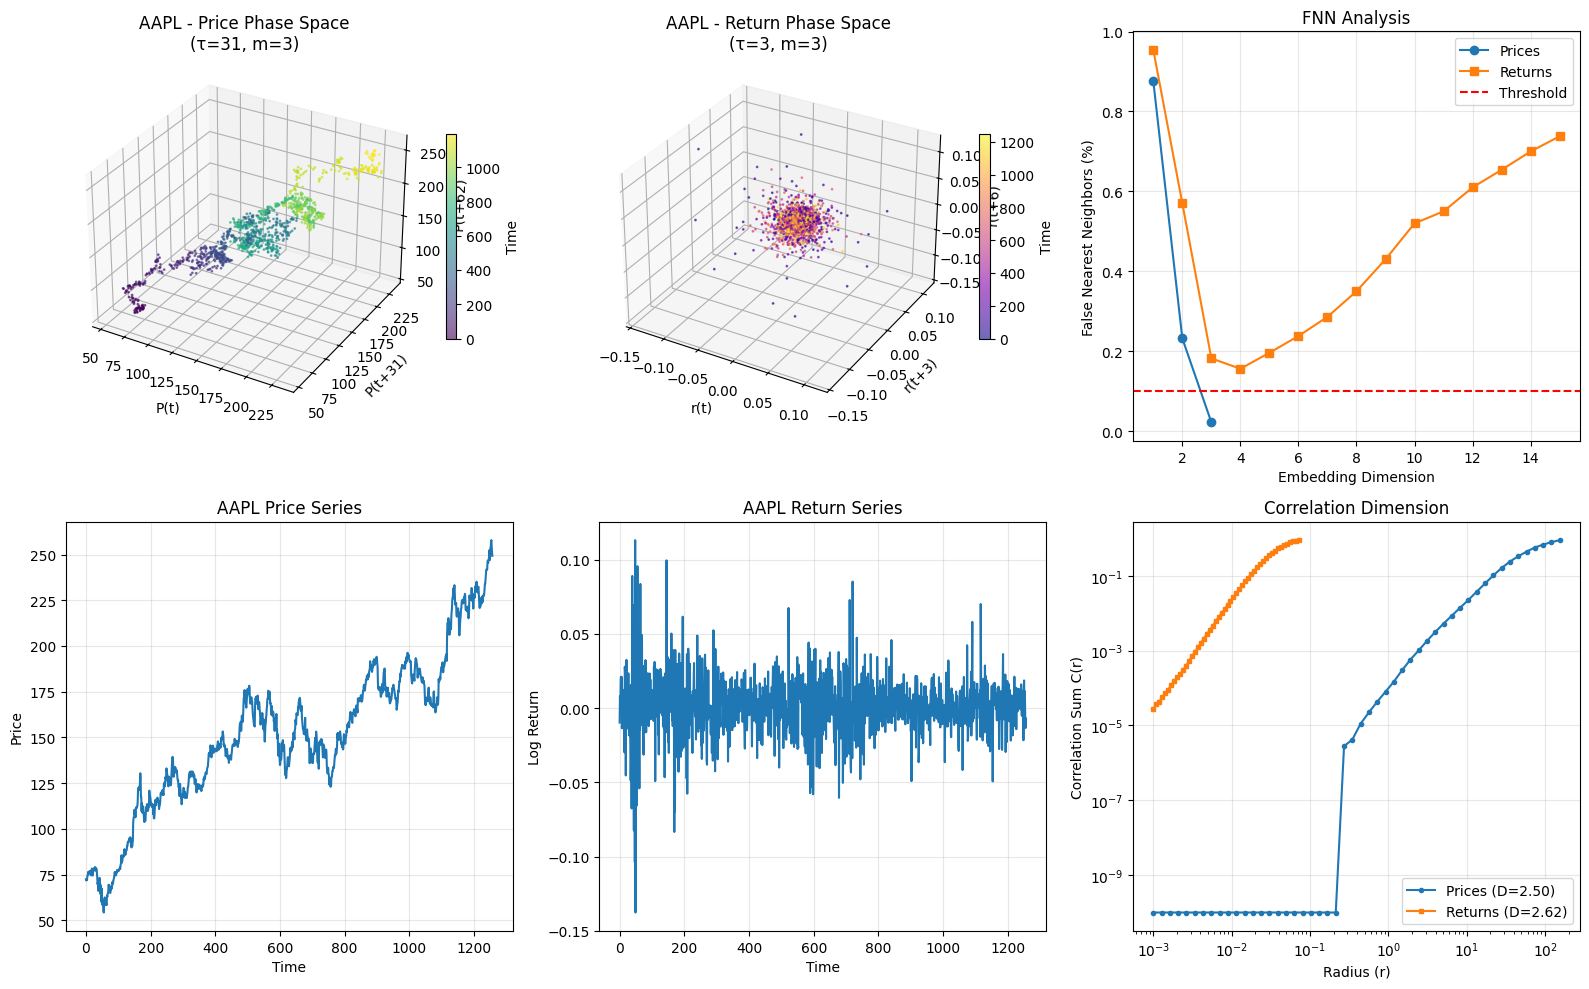


Processing MSFT
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 25
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1208, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.362
Return correlation dimension: 2.593


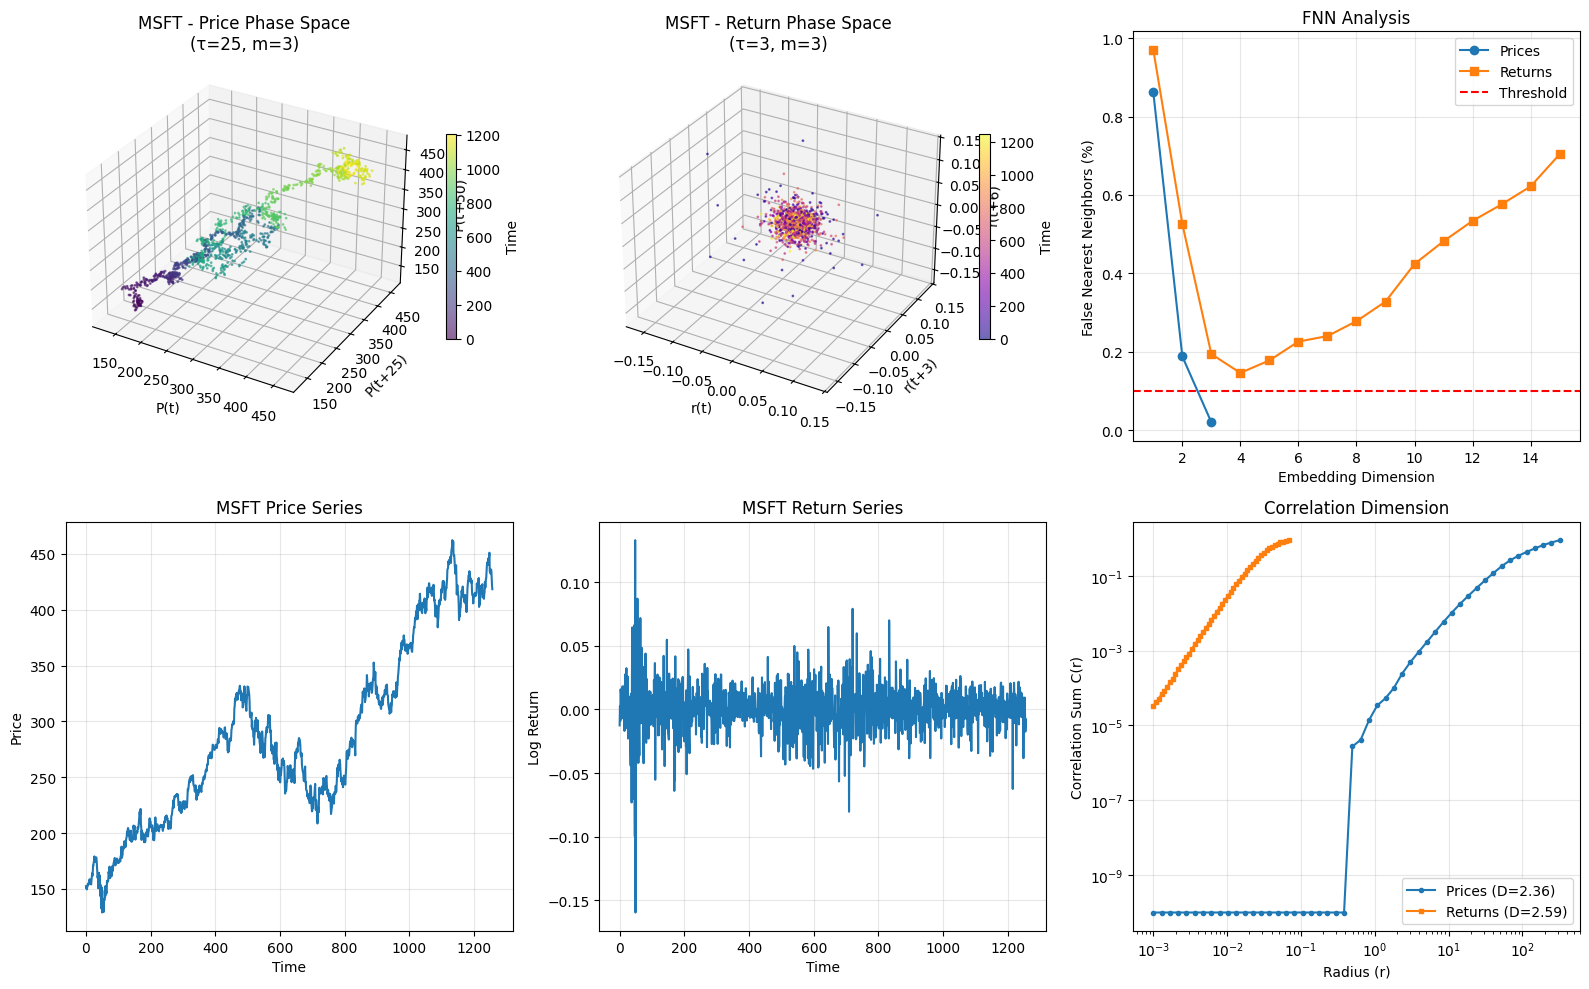


Processing GOOGL
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 21
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1216, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.519
Return correlation dimension: 2.536


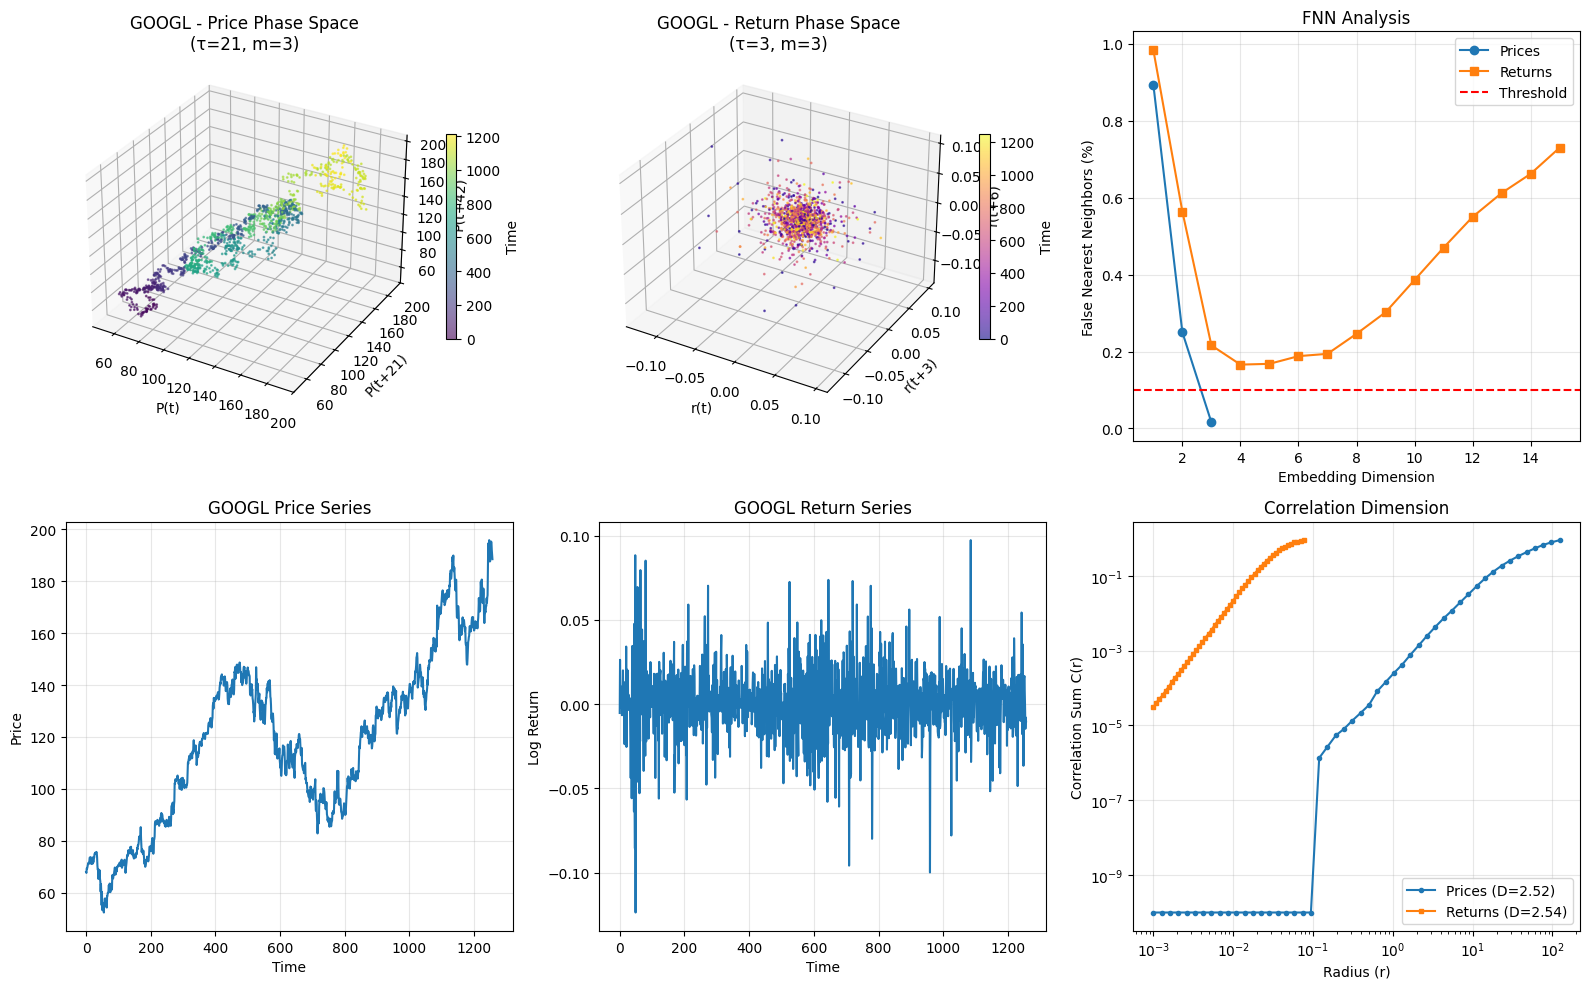


Processing TSLA
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 93, AMI: 25
Returns - ACF: 1, AMI: 2

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1208, 3)
Return Takens matrix shape: (1253, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.297
Return correlation dimension: 2.815


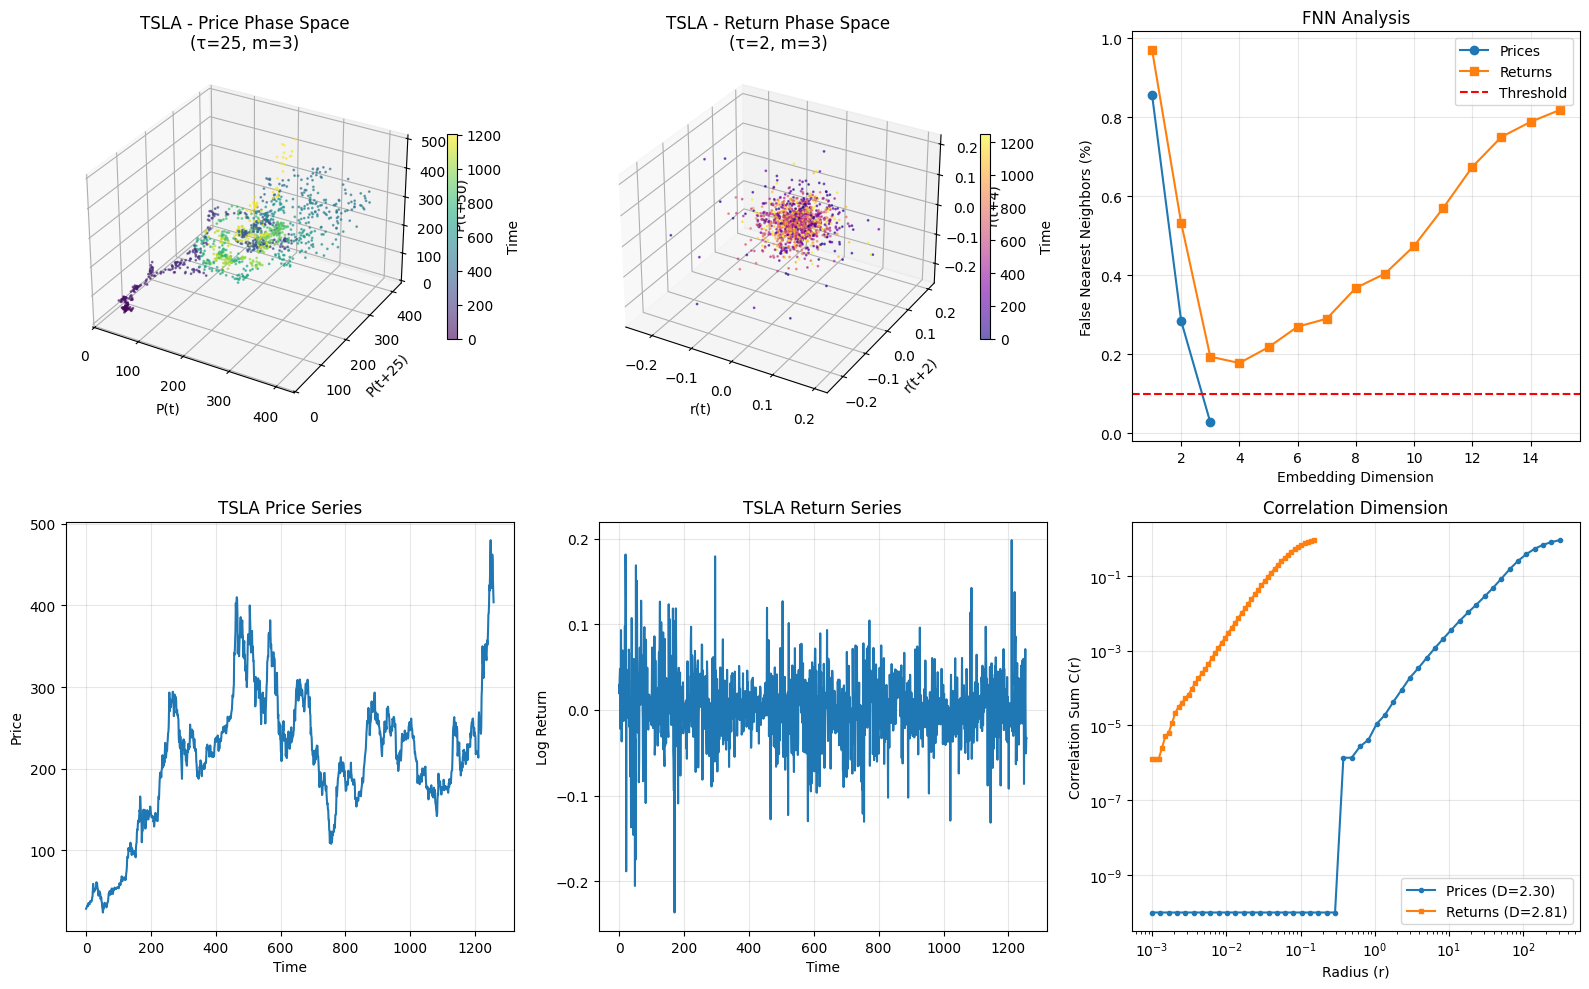


Processing AMZN
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 16
Returns - ACF: 1, AMI: 4

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1226, 3)
Return Takens matrix shape: (1249, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.539
Return correlation dimension: 2.648


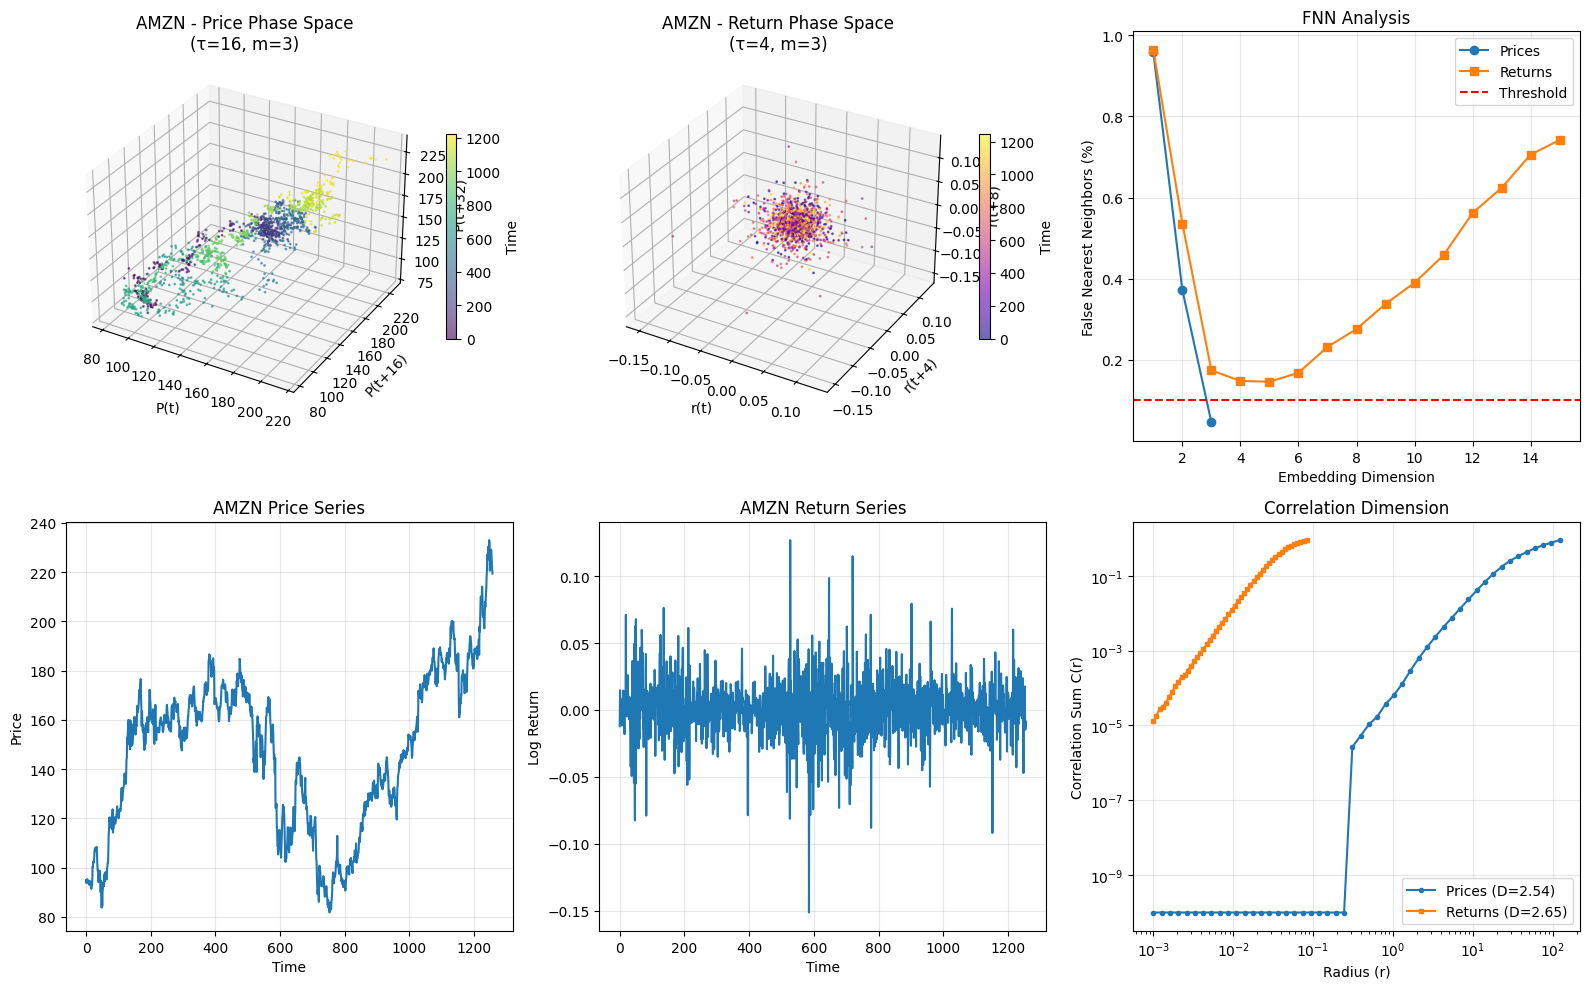


Processing complete!


In [3]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from statsmodels.tsa.stattools import acf
from scipy.stats import entropy

tickers = ["AAPL", "MSFT", "GOOGL", "TSLA", "AMZN"]
start = "2020-01-01"
end = "2025-01-01"
max_lag = 100

def timeLag_acf(series, lag_max=100):
    series = np.array(series).flatten()
    series = series[~np.isnan(series)]
    series = series[~np.isinf(series)]
    
    if len(series) < 10:
        return 1
    
    try:
        nlags = min(lag_max, len(series)//4)
        acf_vals = acf(series, nlags=nlags, fft=True)
        
        first_zero = None
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < 0:
                first_zero = i
                break
        
        if first_zero:
            return first_zero
        
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < 1/np.e:
                return max(1, i)
                
    except:
        return 1
    
    return 1

def timeLag_ami(series, lag_max=100):
    series = np.array(series).flatten()
    series = (series - np.mean(series)) / (np.std(series) + 1e-10)
    
    n_bins = max(10, int(np.sqrt(len(series) / 5)))
    
    def mutual_info(x, y, bins):
        hist_2d, _, _ = np.histogram2d(x, y, bins=bins)
        pxy = hist_2d / (np.sum(hist_2d) + 1e-10)
        px = np.sum(pxy, axis=1) + 1e-10
        py = np.sum(pxy, axis=0) + 1e-10
        
        mi = 0
        for i in range(len(px)):
            for j in range(len(py)):
                if pxy[i, j] > 0:
                    mi += pxy[i, j] * np.log(pxy[i, j] / (px[i] * py[j]))
        return mi
    
    mi_values = []
    for lag in range(1, min(lag_max, len(series)//4)):
        if lag >= len(series):
            break
        mi_val = mutual_info(series[:-lag], series[lag:], n_bins)
        mi_values.append(mi_val)
    
    if len(mi_values) < 3:
        return 1
    
    mi_array = np.array(mi_values)
    
    local_minima = []
    for i in range(1, len(mi_array)-1):
        if mi_array[i] < mi_array[i-1] and mi_array[i] < mi_array[i+1]:
            local_minima.append(i + 1)
    
    if len(local_minima) > 0:
        return local_minima[0]
    
    return np.argmin(mi_array) + 1

def estimateEmbeddingDim(series, time_lag, max_dim=15, threshold=0.1):
    def embed(data, dim, lag):
        n = len(data) - (dim - 1) * lag
        if n <= 0:
            return None
        return np.array([data[i:i + dim * lag:lag] for i in range(n)])
    
    fnn_percentages = []
    
    for dim in range(1, max_dim + 1):
        X1 = embed(series, dim, time_lag)
        X2 = embed(series, dim + 1, time_lag)
        
        if X1 is None or X2 is None or len(X1) < 10 or len(X2) < 10:
            break
        
        rtol = 15.0
        atol = 2.0
        false_neighbors = 0
        n_samples = min(500, len(X1))
        
        for i in range(n_samples):
            distances = np.sqrt(np.sum((X1 - X1[i])**2, axis=1))
            distances[i] = np.inf
            
            nearest_idx = np.argmin(distances)
            
            if nearest_idx >= len(X2):
                continue
            
            d1 = distances[nearest_idx]
            d2 = np.sqrt(np.sum((X2[i] - X2[nearest_idx])**2))
            
            if d1 > 0 and (d2 / d1 > rtol or d2 > atol * np.std(series)):
                false_neighbors += 1
        
        fnn_pct = false_neighbors / n_samples
        fnn_percentages.append(fnn_pct)
        
        if fnn_pct < threshold:
            return dim, fnn_percentages
    
    return max_dim, fnn_percentages

def buildTakens(series, embedding_dim, time_lag):
    n = len(series)
    n_vectors = n - (embedding_dim - 1) * time_lag
    
    if n_vectors <= 0:
        return None
    
    takens_matrix = np.zeros((n_vectors, embedding_dim))
    for i in range(embedding_dim):
        takens_matrix[:, i] = series[i * time_lag : i * time_lag + n_vectors]
    
    return takens_matrix

def corrDim_estimate(series, embedding_dim, time_lag, min_radius=0.001, max_radius=None, n_points=50):
    takens = buildTakens(series, embedding_dim, time_lag)
    
    if takens is None or len(takens) < 10:
        return None, None, None
    
    distances = squareform(pdist(takens, metric='euclidean'))
    
    if max_radius is None:
        max_radius = np.percentile(distances[distances > 0], 90)
    
    radii = np.logspace(np.log10(min_radius), np.log10(max_radius), n_points)
    correlation_sums = []
    
    n = len(takens)
    for r in radii:
        count = np.sum(distances < r) - n
        C_r = count / (n * (n - 1))
        correlation_sums.append(C_r)
    
    correlation_sums = np.array(correlation_sums)
    correlation_sums[correlation_sums <= 0] = 1e-10
    
    log_r = np.log(radii)
    log_C = np.log(correlation_sums)
    
    valid_idx = np.isfinite(log_C) & np.isfinite(log_r)
    
    if np.sum(valid_idx) > 5:
        coeffs = np.polyfit(log_r[valid_idx], log_C[valid_idx], 1)
        corr_dim = coeffs[0]
        return corr_dim, radii, correlation_sums
    
    return None, radii, correlation_sums

for ticker in tickers:
    try:
        print(f"\n{'='*60}")
        print(f"Processing {ticker}")
        print(f"{'='*60}")
        
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
        
        if data.empty or 'Close' not in data.columns:
            print(f"Skipping {ticker}: no data available")
            continue
        
        prices = data['Close'].values
        prices = prices[~np.isnan(prices)]
        
        if len(prices) < 100:
            print(f"Skipping {ticker}: insufficient data")
            continue
        
        log_prices = np.log(prices)
        returns = np.diff(log_prices)
        
        print(f"Data points: {len(prices)} prices, {len(returns)} returns")
        
        print("\n--- Time Lag Estimation ---")
        tau_p_acf = timeLag_acf(prices, max_lag)
        tau_p_ami = timeLag_ami(prices, max_lag)
        tau_r_acf = timeLag_acf(returns, max_lag)
        tau_r_ami = timeLag_ami(returns, max_lag)
        
        print(f"Prices  - ACF: {tau_p_acf}, AMI: {tau_p_ami}")
        print(f"Returns - ACF: {tau_r_acf}, AMI: {tau_r_ami}")
        
        tau_p = tau_p_ami
        tau_r = tau_r_ami
        
        print("\n--- Embedding Dimension Estimation ---")
        emb_dim_p, fnn_p = estimateEmbeddingDim(prices, tau_p, max_dim=15)
        emb_dim_r, fnn_r = estimateEmbeddingDim(returns, tau_r, max_dim=15)
        
        print(f"Prices  - Optimal embedding dimension: {emb_dim_p}")
        print(f"Returns - Optimal embedding dimension: {emb_dim_r}")
        
        m_p = min(emb_dim_p, 3)
        m_r = min(emb_dim_r, 3)
        
        print("\n--- Building Takens Vectors ---")
        Xp = buildTakens(prices, m_p, tau_p)
        Xr = buildTakens(returns, m_r, tau_r)
        
        if Xp is None or Xr is None:
            print(f"Skipping {ticker}: embedding failed")
            continue
        
        print(f"Price Takens matrix shape: {Xp.shape}")
        print(f"Return Takens matrix shape: {Xr.shape}")
        
        print("\n--- Correlation Dimension Estimation ---")
        cd_p, radii_p, corr_p = corrDim_estimate(prices, m_p, tau_p)
        cd_r, radii_r, corr_r = corrDim_estimate(returns, m_r, tau_r)
        
        if cd_p:
            print(f"Price correlation dimension: {cd_p:.3f}")
        if cd_r:
            print(f"Return correlation dimension: {cd_r:.3f}")
        
        fig = plt.figure(figsize=(16, 10))
        
        ax1 = fig.add_subplot(2, 3, 1, projection="3d")
        scatter1 = ax1.scatter(Xp[:,0], Xp[:,1], Xp[:,2], 
                               c=np.arange(len(Xp)), cmap='viridis', s=1, alpha=0.6)
        ax1.set_title(f"{ticker} - Price Phase Space\n(τ={tau_p}, m={m_p})")
        ax1.set_xlabel("P(t)")
        ax1.set_ylabel(f"P(t+{tau_p})")
        ax1.set_zlabel(f"P(t+{2*tau_p})")
        plt.colorbar(scatter1, ax=ax1, label='Time', shrink=0.5)
        
        ax2 = fig.add_subplot(2, 3, 2, projection="3d")
        scatter2 = ax2.scatter(Xr[:,0], Xr[:,1], Xr[:,2], 
                               c=np.arange(len(Xr)), cmap='plasma', s=1, alpha=0.6)
        ax2.set_title(f"{ticker} - Return Phase Space\n(τ={tau_r}, m={m_r})")
        ax2.set_xlabel("r(t)")
        ax2.set_ylabel(f"r(t+{tau_r})")
        ax2.set_zlabel(f"r(t+{2*tau_r})")
        plt.colorbar(scatter2, ax=ax2, label='Time', shrink=0.5)
        
        ax3 = fig.add_subplot(2, 3, 3)
        if fnn_p:
            ax3.plot(range(1, len(fnn_p)+1), fnn_p, 'o-', label='Prices')
        if fnn_r:
            ax3.plot(range(1, len(fnn_r)+1), fnn_r, 's-', label='Returns')
        ax3.axhline(y=0.1, color='r', linestyle='--', label='Threshold')
        ax3.set_xlabel('Embedding Dimension')
        ax3.set_ylabel('False Nearest Neighbors (%)')
        ax3.set_title('FNN Analysis')
        ax3.legend()
        ax3.grid(True, alpha=0.3)
        
        ax4 = fig.add_subplot(2, 3, 4)
        ax4.plot(prices)
        ax4.set_title(f'{ticker} Price Series')
        ax4.set_xlabel('Time')
        ax4.set_ylabel('Price')
        ax4.grid(True, alpha=0.3)
        
        ax5 = fig.add_subplot(2, 3, 5)
        ax5.plot(returns)
        ax5.set_title(f'{ticker} Return Series')
        ax5.set_xlabel('Time')
        ax5.set_ylabel('Log Return')
        ax5.grid(True, alpha=0.3)
        
        ax6 = fig.add_subplot(2, 3, 6)
        if cd_p and corr_p is not None:
            valid = corr_p > 0
            ax6.loglog(radii_p[valid], corr_p[valid], 'o-', label=f'Prices (D={cd_p:.2f})', markersize=3)
        if cd_r and corr_r is not None:
            valid = corr_r > 0
            ax6.loglog(radii_r[valid], corr_r[valid], 's-', label=f'Returns (D={cd_r:.2f})', markersize=3)
        ax6.set_xlabel('Radius (r)')
        ax6.set_ylabel('Correlation Sum C(r)')
        ax6.set_title('Correlation Dimension')
        ax6.legend()
        ax6.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        import traceback
        traceback.print_exc()
        continue

print("\n" + "="*60)
print("Processing complete!")
print("="*60)

Stock Price Delay Coordinate Analysis

Fetching real stock data...
Retrieved 1255 days of data for AAPL

Delay Coordinate Analysis Parameters:
Time delay (τ): 250 days
Embedding dimension (M): 6

Delay vector: y(t) = (g(t), g(t-250), g(t-500))

Generating visualizations...


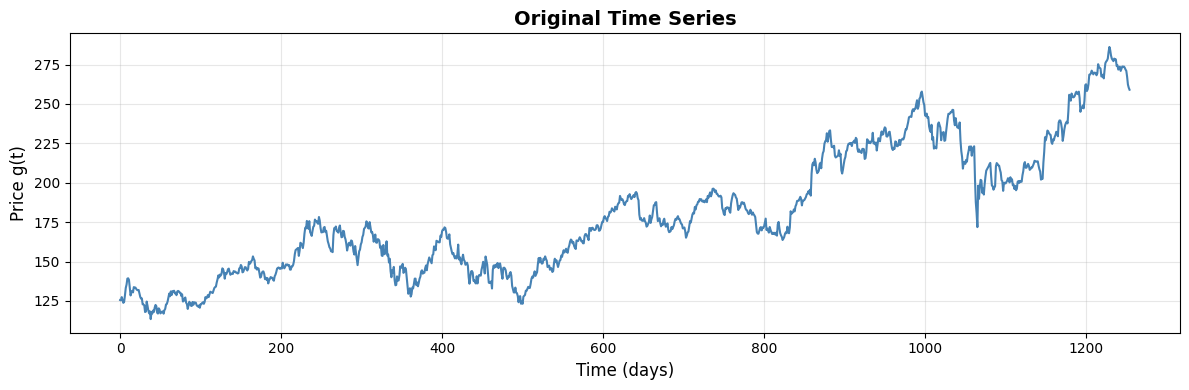

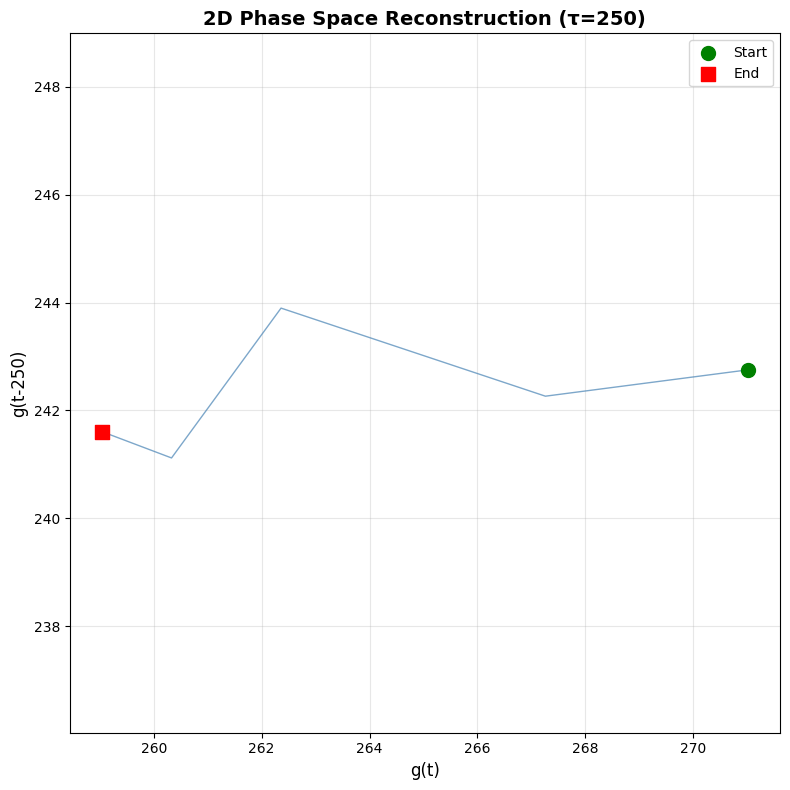


Reconstructed phase space:
  - Number of delay vectors: 5
  - 2D phase space: (g(t), g(t-250))

First 5 delay vectors (2D):
[[271.01000977 242.75212097]
 [267.26000977 242.26431274]
 [262.35998535 243.89691162]
 [260.32998657 241.11949158]
 [259.04000854 241.60725403]]

Analysis complete!

Note: The delay coordinate method reconstructs the
phase space of the system from a single observable g(t).
This allows us to study the underlying dynamics and
potentially reveal fractal or chaotic structures.


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import yfinance as yf
from datetime import datetime, timedelta

class DelayCoordinateAnalysis:
    """
    Implements delay coordinate analysis for stock prices using Takens' embedding theorem.
    
    Given a scalar time series g(t), we construct the delay coordinate vector:
    y(t) = (g(t), g(t-τ), g(t-2τ), ..., g(t-(M-1)τ))
    
    where τ is the time delay and M is the embedding dimension.
    """
    
    def __init__(self, prices, tau=1, embedding_dim=10):
        """
        Initialize the delay coordinate analysis.
        
        Parameters:
        -----------
        prices : array-like
            Time series of stock prices g(t)
        tau : int
            Time delay τ (in units of the sampling interval)
        embedding_dim : int
            Embedding dimension M
        """
        self.prices = np.array(prices)
        self.tau = tau
        self.M = embedding_dim
        
    def construct_delay_vectors(self):
        """
        Construct delay coordinate vectors y(t) = (g(t), g(t-τ), ..., g(t-(M-1)τ))
        
        Returns:
        --------
        delay_vectors : ndarray, shape (n_samples, M)
            Matrix where each row is a delay coordinate vector
        """
        n = len(self.prices)
        max_delay = (self.M - 1) * self.tau
        n_vectors = n - max_delay
        
        delay_vectors = np.zeros((n_vectors, self.M))
        
        for i in range(n_vectors):
            for j in range(self.M):
                # y^(j)(t) = g(t - j*τ)
                delay_vectors[i, j] = self.prices[i + max_delay - j * self.tau]
        
        return delay_vectors
    
    def plot_original_series(self):
        """Plot the original time series g(t)"""
        plt.figure(figsize=(12, 4))
        plt.plot(self.prices, linewidth=1.5, color='steelblue')
        plt.xlabel('Time (days)', fontsize=12)
        plt.ylabel('Price g(t)', fontsize=12)
        plt.title('Original Time Series', fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    
    def plot_2d_phase_space(self):
        """
        Plot 2D phase space reconstruction: (g(t), g(t-τ))
        """
        delay_vectors = self.construct_delay_vectors()
        
        plt.figure(figsize=(8, 8))
        plt.plot(delay_vectors[:, 0], delay_vectors[:, 1], 
                linewidth=1, color='steelblue', alpha=0.7)
        plt.scatter(delay_vectors[0, 0], delay_vectors[0, 1], 
                   c='green', s=100, marker='o', label='Start', zorder=5)
        plt.scatter(delay_vectors[-1, 0], delay_vectors[-1, 1], 
                   c='red', s=100, marker='s', label='End', zorder=5)
        plt.xlabel(f'g(t)', fontsize=12)
        plt.ylabel(f'g(t-{self.tau})', fontsize=12)
        plt.title(f'2D Phase Space Reconstruction (τ={self.tau})', 
                 fontsize=14, fontweight='bold')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.axis('equal')
        plt.tight_layout()
        plt.show()
    
    def plot_3d_phase_space(self):
        """
        Plot 3D phase space reconstruction: (g(t), g(t-τ), g(t-2τ))
        """
        delay_vectors = self.construct_delay_vectors()
        
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        
        ax.plot(delay_vectors[:, 0], 
                delay_vectors[:, 1], 
                delay_vectors[:, 2],
                linewidth=1, color='steelblue', alpha=0.7)
        
        # Mark start and end points
        ax.scatter(delay_vectors[0, 0], delay_vectors[0, 1], delay_vectors[0, 2],
                  c='green', s=100, marker='o', label='Start')
        ax.scatter(delay_vectors[-1, 0], delay_vectors[-1, 1], delay_vectors[-1, 2],
                  c='red', s=100, marker='s', label='End')
        
        ax.set_xlabel(f'g(t)', fontsize=11)
        ax.set_ylabel(f'g(t-{self.tau})', fontsize=11)
        ax.set_zlabel(f'g(t-{2*self.tau})', fontsize=11)
        ax.set_title(f'3D Phase Space Reconstruction (τ={self.tau})', 
                    fontsize=14, fontweight='bold')
        ax.legend()
        plt.tight_layout()
        plt.show()
    
    def plot_all(self):
        """Generate all plots"""
        self.plot_original_series()
        self.plot_2d_phase_space()


def fetch_stock_data(symbol='AAPL', period='5y'):
    """
    Fetch stock price data using yfinance.
    
    Parameters:
    -----------
    symbol : str
        Stock ticker symbol
    period : str
        Time period (e.g., '1y', '6mo', '1mo')
    
    Returns:
    --------
    prices : ndarray
        Array of closing prices
    """
    stock = yf.Ticker(symbol)
    hist = stock.history(period=period)
    return hist['Close'].values


def generate_synthetic_data(n=200, initial_price=100, trend=0.0005, volatility=0.02):
    """
    Generate synthetic stock price data (geometric random walk).
    
    Parameters:
    -----------
    n : int
        Number of time steps
    initial_price : float
        Starting price
    trend : float
        Daily drift
    volatility : float
        Daily volatility
    
    Returns:
    --------
    prices : ndarray
        Synthetic price series
    """
    prices = [initial_price]
    for _ in range(n-1):
        change = trend + volatility * np.random.randn()
        new_price = prices[-1] * (1 + change)
        prices.append(new_price)
    return np.array(prices)


# Example usage
if __name__ == "__main__":
    print("Stock Price Delay Coordinate Analysis")
    print("=" * 50)
    
    # Choose data source
    use_real_data = True  # Set to True to use real stock data
    
    if use_real_data:
        print("\nFetching real stock data...")
        try:
            prices = fetch_stock_data('AAPL', period='5y')
            print(f"Retrieved {len(prices)} days of data for AAPL")
        except:
            print("Failed to fetch real data, using synthetic data instead")
            use_real_data = False
    
    if not use_real_data:
        print("\nGenerating synthetic stock price data...")
        np.random.seed(42)
        prices = generate_synthetic_data(n=250)
        print(f"Generated {len(prices)} days of synthetic data")
    
    # Perform delay coordinate analysis
    print("\n" + "=" * 50)
    print("Delay Coordinate Analysis Parameters:")
    print("=" * 50)
    
    tau = 250 # Time delay
    embedding_dim = 6  # Embedding dimension
    
    print(f"Time delay (τ): {tau} days")
    print(f"Embedding dimension (M): {embedding_dim}")
    print(f"\nDelay vector: y(t) = (g(t), g(t-{tau}), g(t-{2*tau}))")
    
    # Create analyzer and generate plots
    analyzer = DelayCoordinateAnalysis(prices, tau=tau, embedding_dim=embedding_dim)
    
    print("\nGenerating visualizations...")
    analyzer.plot_all()
    
    # Additional analysis: compute delay vectors
    delay_vectors = analyzer.construct_delay_vectors()
    print(f"\nReconstructed phase space:")
    print(f"  - Number of delay vectors: {len(delay_vectors)}")
    print(f"  - 2D phase space: (g(t), g(t-{tau}))")
    print(f"\nFirst 5 delay vectors (2D):")
    print(delay_vectors[:5, :2])
    
    print("\n" + "=" * 50)
    print("Analysis complete!")
    print("\nNote: The delay coordinate method reconstructs the")
    print("phase space of the system from a single observable g(t).")
    print("This allows us to study the underlying dynamics and")
    print("potentially reveal fractal or chaotic structures.")

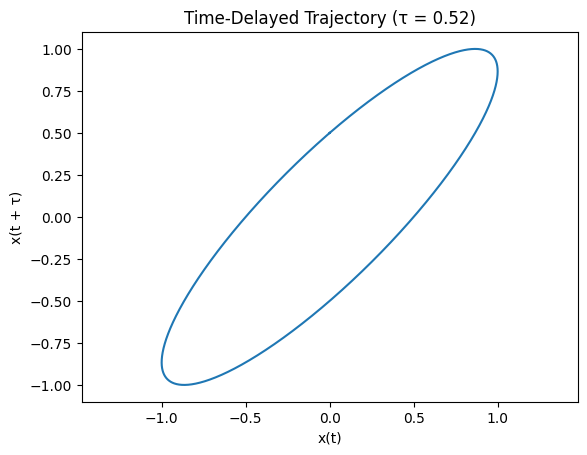

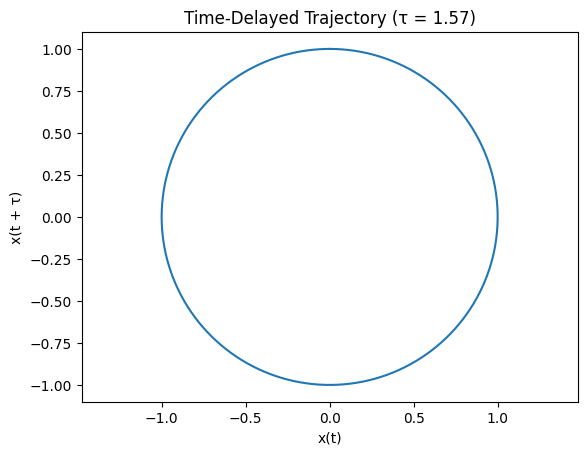

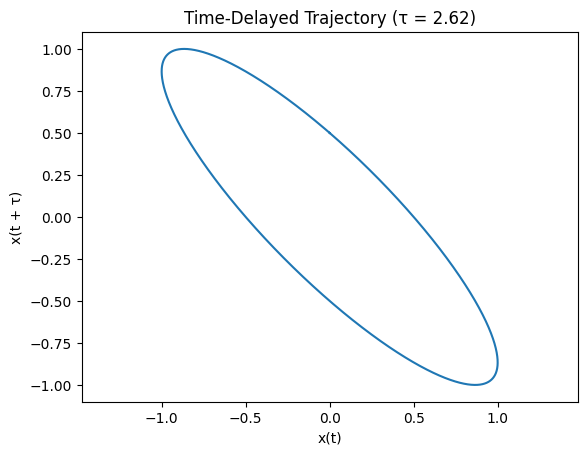

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# time axis
t = np.linspace(0, 2*np.pi, 2000)

# signal
x = np.sin(t)

# delay values
taus = [np.pi/6, np.pi/2, 5*np.pi/6]

for tau in taus:
    x_tau = np.sin(t + tau)

    plt.figure()
    plt.plot(x, x_tau)
    plt.xlabel("x(t)")
    plt.ylabel("x(t + τ)")
    plt.title(f"Time-Delayed Trajectory (τ = {tau:.2f})")
    plt.axis("equal")
    plt.show()


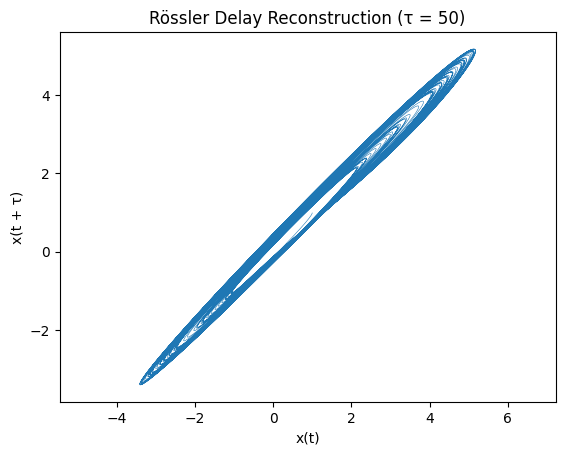

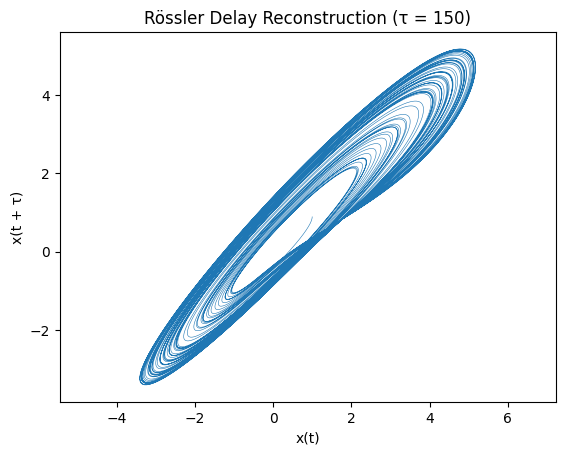

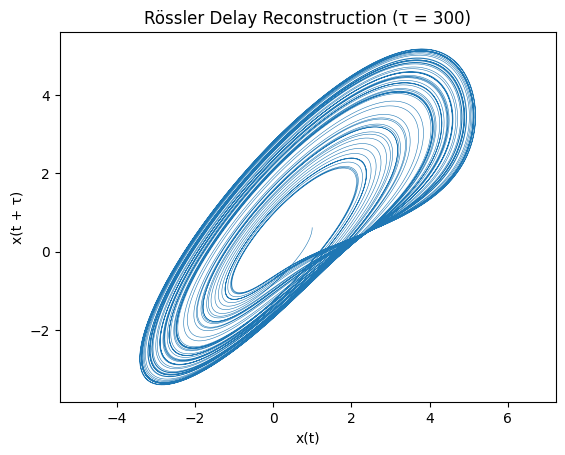

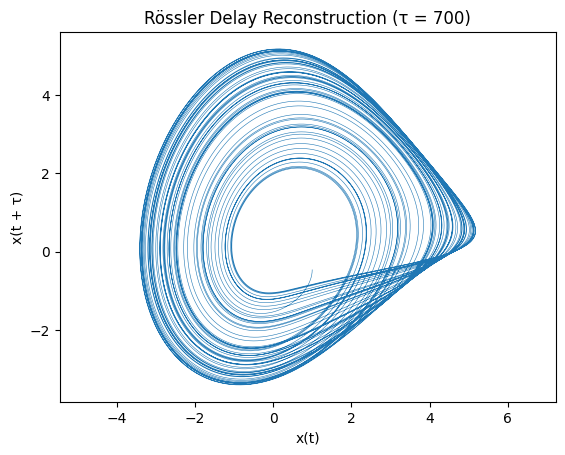

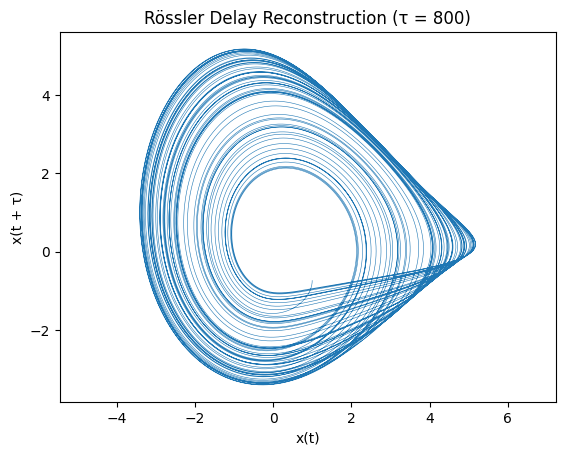

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Rössler parameters
a, b, c = 0.4, 2.0, 4.0

# Rössler system
def rossler(t, state):
    x, y, z = state
    return [
        -y - z,
        x + a*y,
        b + z*(x - c)
    ]

# Integrate system
t_span = (0, 400)
t_eval = np.linspace(0, 400, 200000)
x0 = [1.0, 0.0, 0.0]

sol = solve_ivp(rossler, t_span, x0, t_eval=t_eval)

# Extract x(t) and discard transient
x = sol.y[0]

# Delay values (in samples)
taus = [50, 150, 300, 700, 800]

# Delay embedding plots
for tau in taus:
    x_tau = np.roll(x, -tau)

    plt.figure()
    plt.plot(x[:-tau], x_tau[:-tau], linewidth=0.4)
    plt.xlabel("x(t)")
    plt.ylabel("x(t + τ)")
    plt.title(f"Rössler Delay Reconstruction (τ = {tau})")
    plt.axis("equal")
    plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_21352\1540679147.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start, end=end, progress=False)


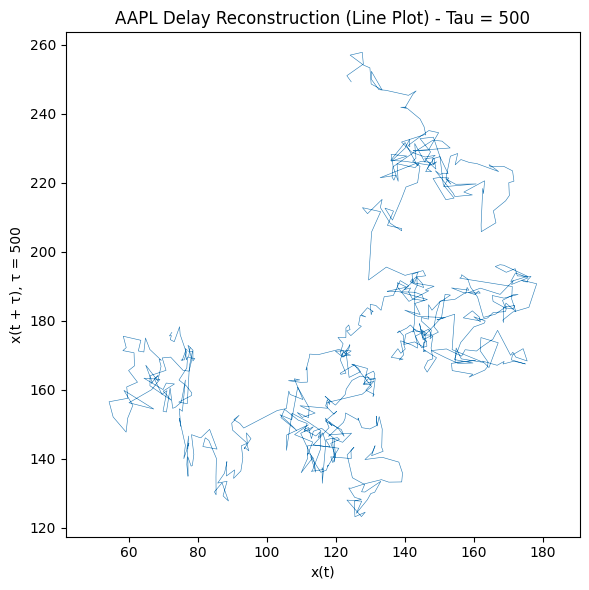

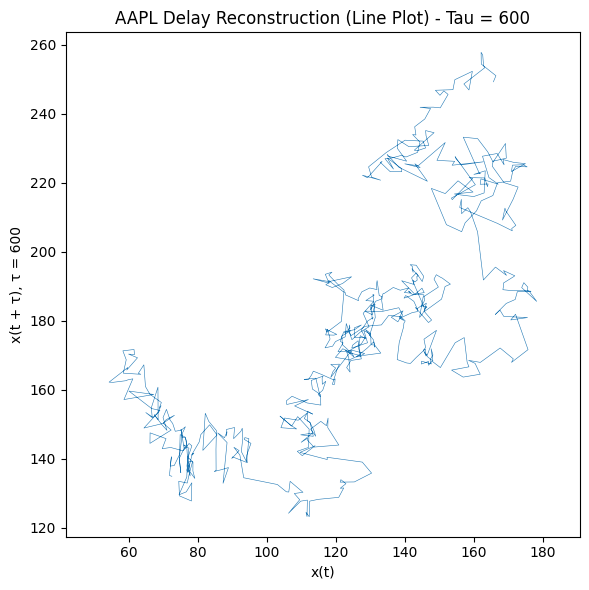

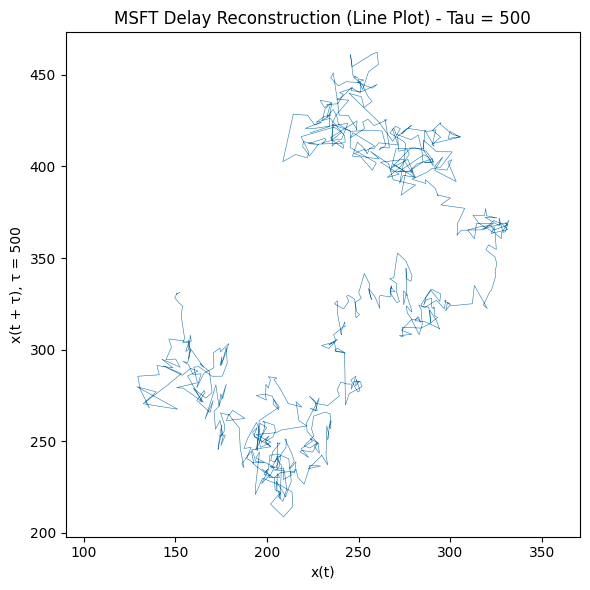

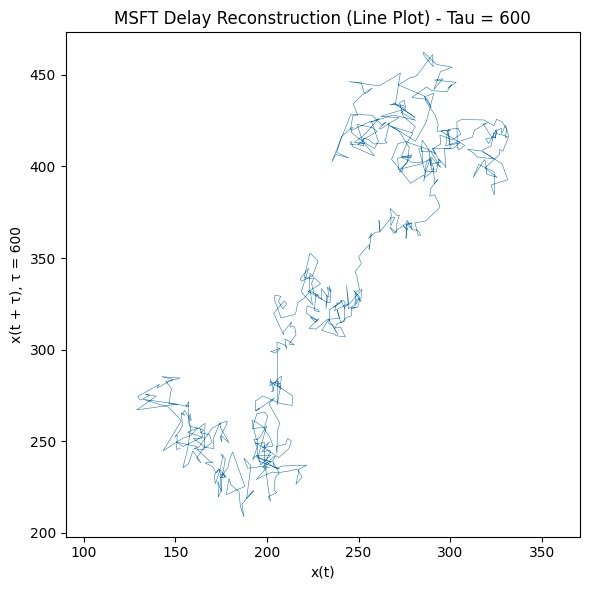

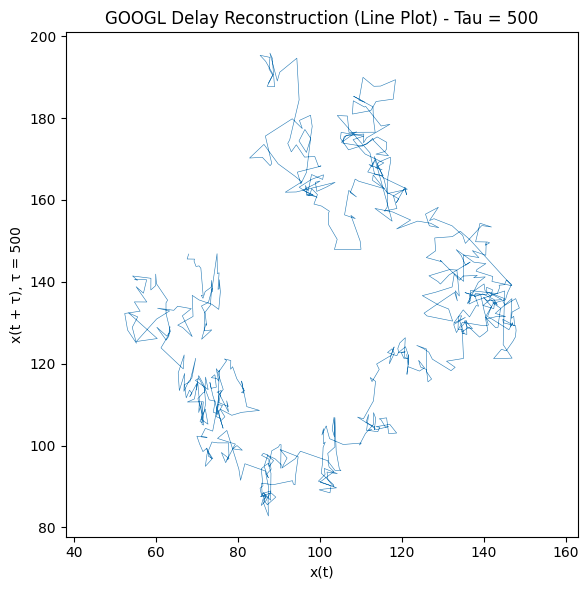

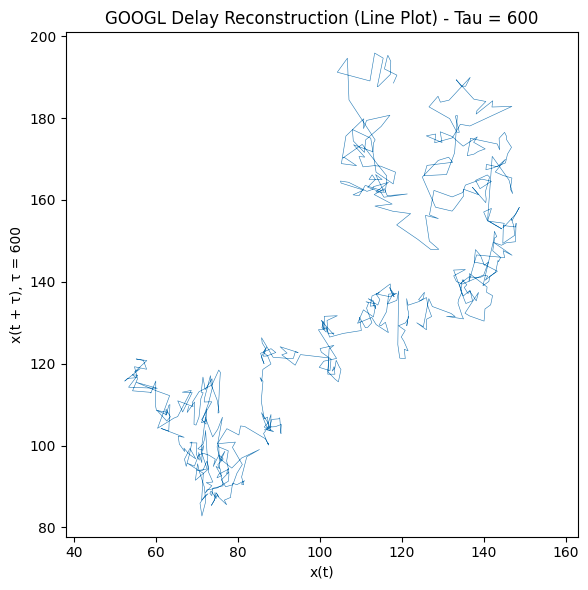

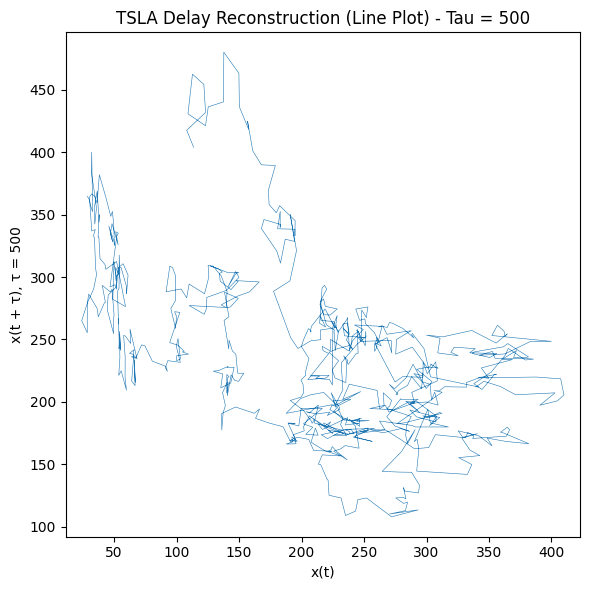

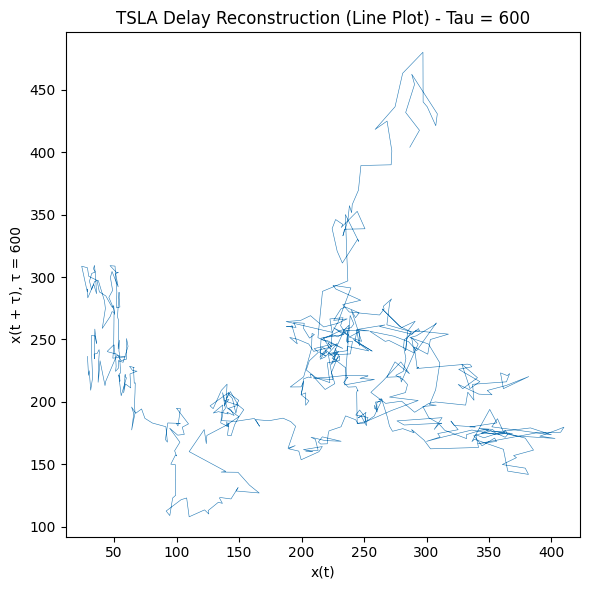

In [12]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
tickers = ["AAPL", "MSFT", "GOOGL", "TSLA"]
start = "2020-01-01"
end = "2025-01-01"

# delays in trading days
taus = [500, 600]

# -----------------------------
# Download data
# -----------------------------
data = yf.download(tickers, start=start, end=end, progress=False)
prices = data["Close"].dropna()

# -----------------------------
# Delay reconstruction plots
# -----------------------------
for ticker in tickers:
    x = prices[ticker].values


    for tau in taus:
        if tau >= len(x) // 2:
            continue

        x_tau = np.roll(x, -tau)

        plt.figure(figsize=(6, 6))
        plt.plot(
            x[:-tau],
            x_tau[:-tau],
            linewidth=0.4
        )

        plt.xlabel("x(t)")
        plt.ylabel(f"x(t + τ), τ = {tau}")
        plt.title(f"{ticker} Delay Reconstruction (Line Plot) - Tau = {tau}")
        plt.axis("equal")
        plt.tight_layout()
        plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\2833125760.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\2833125760.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\2833125760.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\2833125760.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\2833125760.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  

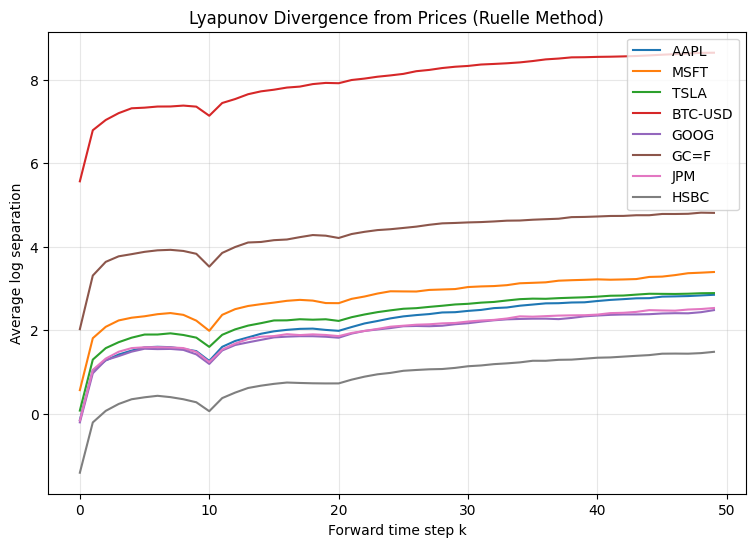

In [2]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# -----------------------------
# Parameters
# -----------------------------
start = "2015-01-01"
end = "2025-01-01"

m = 3          # embedding dimension
tau = 10       # delay (in trading days)
theiler = 50   # temporal exclusion window
max_k = 50     # forward evolution steps

# -----------------------------
# Delay embedding
# -----------------------------
def delay_embedding(x, m, tau):
    x = np.asarray(x).reshape(-1)
    N = len(x) - (m - 1) * tau
    if N <= 0:
        raise ValueError("Time series too short")
    X = np.empty((N, m))
    for i in range(m):
        X[:, i] = x[i * tau : i * tau + N]
    return X

# -----------------------------
# Lyapunov divergence curve
# -----------------------------
def lyapunov_divergence(x, m, tau, theiler, max_k):
    X = delay_embedding(x, m, tau)

    nbrs = NearestNeighbors(n_neighbors=2).fit(X)
    _, indices = nbrs.kneighbors(X)

    pairs = []
    for i in range(len(X)):
        j = indices[i, 1]
        if abs(j - i) > theiler:
            pairs.append((i, j))

    log_sep = np.zeros(max_k)
    counts = np.zeros(max_k)

    for i, j in pairs:
        for k in range(max_k):
            if i + k < len(X) and j + k < len(X):
                d = np.linalg.norm(X[i + k] - X[j + k])
                if d > 1e-12:
                    log_sep[k] += np.log(d)
                    counts[k] += 1

    valid = counts > 0
    log_sep[valid] /= counts[valid]

    return log_sep

# -----------------------------
# Run experiment
# -----------------------------
plt.figure(figsize=(9,6))
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC"]
for ticker in tickers:
    data = yf.download(ticker, start=start, end=end, progress=False)
    x = data["Close"].dropna().values

    log_sep = lyapunov_divergence(x, m, tau, theiler, max_k)

    plt.plot(
        log_sep,
        linewidth=1.5,
        label=ticker
    )

plt.xlabel("Forward time step k")
plt.ylabel("Average log separation")
plt.title("Lyapunov Divergence from Prices (Ruelle Method)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\3524689575.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\3524689575.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\3524689575.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\3524689575.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_4976\3524689575.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  

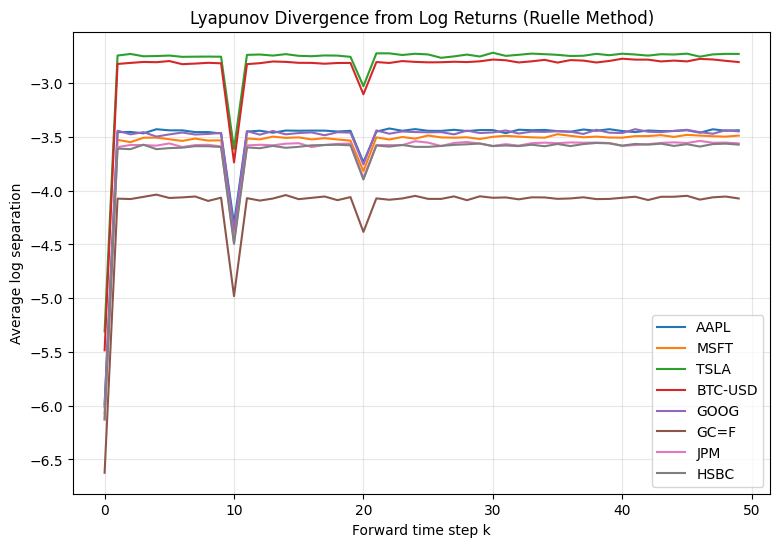

In [1]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# -----------------------------
# Parameters
# -----------------------------
start = "2015-01-01"
end = "2025-01-01"

m = 3          # embedding dimension
tau = 10       # delay (in trading days)
theiler = 50   # temporal exclusion window
max_k = 50     # forward evolution steps

# -----------------------------
# Delay embedding
# -----------------------------
def delay_embedding(x, m, tau):
    x = np.asarray(x).reshape(-1)
    N = len(x) - (m - 1) * tau
    if N <= 0:
        raise ValueError("Time series too short")
    X = np.empty((N, m))
    for i in range(m):
        X[:, i] = x[i * tau : i * tau + N]
    return X

# -----------------------------
# Lyapunov divergence curve
# -----------------------------
def lyapunov_divergence(x, m, tau, theiler, max_k):
    X = delay_embedding(x, m, tau)

    nbrs = NearestNeighbors(n_neighbors=2).fit(X)
    _, indices = nbrs.kneighbors(X)

    pairs = []
    for i in range(len(X)):
        j = indices[i, 1]
        if abs(j - i) > theiler:
            pairs.append((i, j))

    log_sep = np.zeros(max_k)
    counts = np.zeros(max_k)

    for i, j in pairs:
        for k in range(max_k):
            if i + k < len(X) and j + k < len(X):
                d = np.linalg.norm(X[i + k] - X[j + k])
                if d > 1e-12:
                    log_sep[k] += np.log(d)
                    counts[k] += 1

    valid = counts > 0
    log_sep[valid] /= counts[valid]

    return log_sep

# -----------------------------
# Run experiment
# -----------------------------
plt.figure(figsize=(9,6))
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC"]
for ticker in tickers:
    data = yf.download(ticker, start=start, end=end, progress=False)
    x = data["Close"].dropna().values
    log_returns = np.log(x[1:] / x[:-1])
    x = log_returns.reshape(-1)
    log_sep = lyapunov_divergence(x, m, tau, theiler, max_k)

    plt.plot(
        log_sep,
        linewidth=1.5,
        label=ticker
    )

plt.xlabel("Forward time step k")
plt.ylabel("Average log separation")
plt.title("Lyapunov Divergence from Log Returns (Ruelle Method)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10296\2938614442.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10296\2938614442.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10296\2938614442.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10296\2938614442.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10296\2938614442.py:67: FutureWarning: YF.download() has changed argument auto_adjust default to Tr

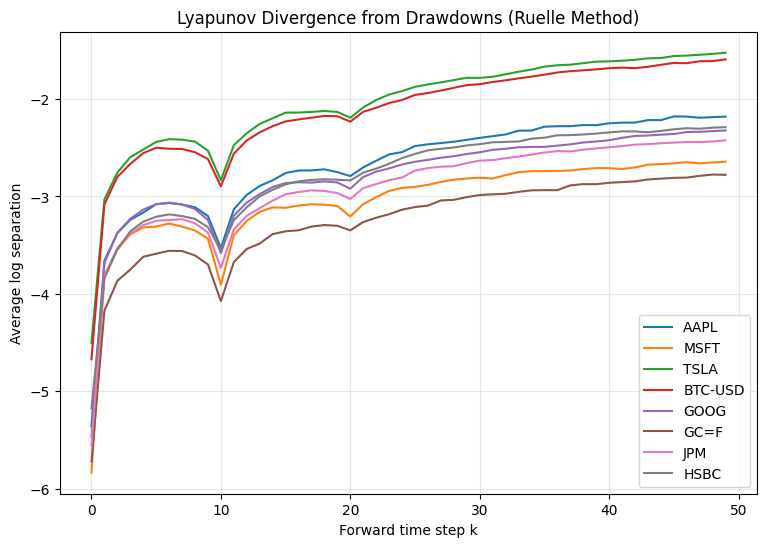

In [2]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# -----------------------------
# Parameters
# -----------------------------
start = "2015-01-01"
end = "2025-01-01"

m = 3          # embedding dimension
tau = 10       # delay (in trading days)
theiler = 50   # temporal exclusion window
max_k = 50     # forward evolution steps

# -----------------------------
# Delay embedding
# -----------------------------
def delay_embedding(x, m, tau):
    x = np.asarray(x).reshape(-1)
    N = len(x) - (m - 1) * tau
    if N <= 0:
        raise ValueError("Time series too short")
    X = np.empty((N, m))
    for i in range(m):
        X[:, i] = x[i * tau : i * tau + N]
    return X

# -----------------------------
# Lyapunov divergence curve
# -----------------------------
def lyapunov_divergence(x, m, tau, theiler, max_k):
    X = delay_embedding(x, m, tau)

    nbrs = NearestNeighbors(n_neighbors=2).fit(X)
    _, indices = nbrs.kneighbors(X)

    pairs = []
    for i in range(len(X)):
        j = indices[i, 1]
        if abs(j - i) > theiler:
            pairs.append((i, j))

    log_sep = np.zeros(max_k)
    counts = np.zeros(max_k)

    for i, j in pairs:
        for k in range(max_k):
            if i + k < len(X) and j + k < len(X):
                d = np.linalg.norm(X[i + k] - X[j + k])
                if d > 1e-12:
                    log_sep[k] += np.log(d)
                    counts[k] += 1

    valid = counts > 0
    log_sep[valid] /= counts[valid]

    return log_sep

# -----------------------------
# Run experiment
# -----------------------------
plt.figure(figsize=(9,6))
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC"]
for ticker in tickers:
    data = yf.download(ticker, start=start, end=end, progress=False)
    prices = data["Close"].dropna().values

    running_max = np.maximum.accumulate(prices)
    drawdowns = prices / running_max - 1.0

    x = drawdowns.reshape(-1)

    log_sep = lyapunov_divergence(x, m, tau, theiler, max_k)

    plt.plot(
        log_sep,
        linewidth=1.5,
        label=ticker
    )

plt.xlabel("Forward time step k")
plt.ylabel("Average log separation")
plt.title("Lyapunov Divergence from Drawdowns (Ruelle Method)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


CHECK WHETHER FOLLOWING FRACTAL RANDOM WALK

In [10]:
import numpy as np
import yfinance as yf
import pandas as pd
import warnings

# Suppress yfinance multi-index warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC"]
start = "2020-01-01"
end = "2025-01-01"

# -----------------------------
# Functions
# -----------------------------
def hurst_exponent(ts, max_lag=20):
    ts = np.array(ts)
    lags = range(2, min(max_lag, len(ts)//2))
    if len(lags) < 2:
        return np.nan
    
    # Standard Hurst via variance of lags
    tau = [np.sqrt(np.std(ts[lag:] - ts[:-lag])) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0]

def generalized_hurst(ts, q_vals=[1,2,3], min_scale=5, max_scale=30):
    ts = np.array(ts)
    Hq = {}

    # Ensure we have enough data
    max_len = len(ts) // 2
    actual_max_scale = min(max_scale, max_len)
    valid_scales = [s for s in range(min_scale, actual_max_scale + 1)]

    if len(valid_scales) < 2:
        return {q: np.nan for q in q_vals}

    for q in q_vals:
        Fq = []
        for s in valid_scales:
            segments = len(ts) // s
            # Reshape into non-overlapping segments
            reshaped = ts[:segments*s].reshape(segments, s)
            # Calculate fluctuation per segment
            rm_mean = reshaped - reshaped.mean(axis=1, keepdims=True)
            # Standard MFDFA fluctuation function
            f_s = (np.mean(np.abs(rm_mean)**q, axis=1)**(1/q)).mean()
            Fq.append(f_s)
            
        poly = np.polyfit(np.log(valid_scales), np.log(Fq), 1)
        Hq[q] = poly[0]
    return Hq

def is_multifractal(Hq, threshold=0.05):
    values = [v for v in Hq.values() if not np.isnan(v)]
    if len(values) < 2:
        return False
    # If H(q) varies significantly with q, it is multifractal
    return (max(values) - min(values)) > threshold

# -----------------------------
# Fetch data and analyze
# -----------------------------
results = []

for ticker in tickers:
    # Use auto_adjust to simplify column access
    data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
    
    if data.empty:
        continue

    # FIX: Handle MultiIndex columns by selecting just the Series
    if isinstance(data.columns, pd.MultiIndex):
        prices = data["Close"][ticker].dropna().values
    else:
        prices = data["Close"].dropna().values

    if len(prices) < 50:
        print(f"{ticker}: Not enough data")
        continue

    log_returns = np.diff(np.log(prices))

    # Hurst exponent
    H_price = hurst_exponent(prices)
    H_logr = hurst_exponent(log_returns)

    # Multifractal H(q)
    Hq_price = generalized_hurst(prices, q_vals=[1,2,3])
    Hq_logr = generalized_hurst(log_returns, q_vals=[1,2,3])

    results.append({
        "Ticker": ticker,
        "H_price": round(H_price, 3),
        "H_logr": round(H_logr, 3),
        "Hq1_price": round(Hq_price[1], 3),
        "Hq2_price": round(Hq_price[2], 3),
        "Hq3_price": round(Hq_price[3], 3),
        "Multi_P": "Yes" if is_multifractal(Hq_price) else "No",
        "Hq1_logr": round(Hq_logr[1], 3),
        "Hq2_logr": round(Hq_logr[2], 3),
        "Hq3_logr": round(Hq_logr[3], 3),
        "Multi_R": "Yes" if is_multifractal(Hq_logr) else "No",
    })

# -----------------------------
# Display table
# -----------------------------
df = pd.DataFrame(results)
df

,Ticker,H_price,H_logr,Hq1_price,Hq2_price,Hq3_price,Multi_P,Hq1_logr,Hq2_logr,Hq3_logr,Multi_R
0,AAPL,0.242,-0.001,0.542,0.548,0.555,No,0.041,0.083,0.120,Yes
1,MSFT,0.230,0.003,0.480,0.494,0.507,No,0.037,0.079,0.116,Yes
2,TSLA,0.268,0.005,0.558,0.567,0.578,No,0.031,0.083,0.128,Yes
3,BTC-USD,0.261,0.004,0.534,0.544,0.555,No,0.026,0.092,0.149,Yes
4,GOOG,0.225,0.000,0.493,0.509,0.523,No,0.027,0.082,0.131,Yes
5,GC=F,0.225,0.002,0.490,0.503,0.517,No,0.032,0.081,0.125,Yes
6,JPM,0.244,0.007,0.533,0.543,0.553,No,0.049,0.100,0.149,Yes
7,HSBC,0.255,0.002,0.556,0.560,0.567,No,0.031,0.091,0.148,Yes


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.stats import genextreme, genpareto

# ============================================================
# Parameters
# ============================================================
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC"]
start = "2018-01-01"
end   = "2025-01-01"

block_size = 21          # ~1 trading month
threshold_q = 0.95       # POT threshold

np.random.seed(42)

# ============================================================
# 1. Download price data
# ============================================================
prices = yf.download(tickers, start=start, end=end)["Close"]

print("\nDownloaded adjusted close prices")
print(prices.tail())
print("=" * 70)

# ============================================================
# 2. Compute log-returns and losses
# ============================================================
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns  # EVT works on extreme losses

print("Computed daily log-returns")
print("Converted to losses (negative returns)")
print("=" * 70)

# ============================================================
# 3. EVT per asset
# ============================================================
results = []

for ticker in tickers:
    print(f"\n===== EVT ANALYSIS FOR {ticker} =====")

    x = losses[ticker].dropna().values
    n = len(x)

    print(f"Number of observations: {n}")

    # --------------------------------------------------------
    # BLOCK MAXIMA → GEV
    # --------------------------------------------------------
    num_blocks = n // block_size
    blocks = x[:num_blocks * block_size].reshape(num_blocks, block_size)
    block_maxima = blocks.max(axis=1)

    print(f"Block size: {block_size}")
    print(f"Number of blocks: {num_blocks}")
    print("Fitting GEV to block maxima...")

    # SciPy uses opposite sign convention for ξ
    xi_gev, mu_gev, sigma_gev = genextreme.fit(block_maxima)

    print(f"GEV shape ξ   : {xi_gev:.4f}")
    print(f"GEV location : {mu_gev:.4f}")
    print(f"GEV scale    : {sigma_gev:.4f}")

    if xi_gev > 0:
        print("→ Fréchet domain (heavy-tailed extremes)")
    elif np.isclose(xi_gev, 0, atol=0.05):
        print("→ Gumbel domain (light-tailed extremes)")
    else:
        print("→ Weibull domain (finite upper bound)")

    # --------------------------------------------------------
    # THRESHOLD EXCEEDANCES → GPD
    # --------------------------------------------------------
    u = np.quantile(x, threshold_q)
    exceedances = x[x > u] - u

    print(f"\nThreshold (q={threshold_q}): {u:.5f}")
    print(f"Number of exceedances: {len(exceedances)}")
    print("Fitting GPD to exceedances...")

    xi_gpd, _, beta_gpd = genpareto.fit(exceedances, floc=0)

    print(f"GPD shape ξ : {xi_gpd:.4f}")
    print(f"GPD scale β: {beta_gpd:.4f}")

    print("Interpretation:")
    print("Same ξ (GEV ≈ GPD) → tail property of the asset")

    results.append({
        "Ticker": ticker,
        "GEV_xi": xi_gev,
        "GPD_xi": xi_gpd
    })

    print("=" * 70)

# ============================================================
# 4. Summary table
# ============================================================
summary = pd.DataFrame(results)

print("\nSUMMARY OF TAIL INDICES")
print(summary)
print("\nKey:")
print("ξ > 0  → heavy-tailed risk (common in finance)")
print("ξ ≈ 0  → light-tailed (rare for returns)")
print("ξ < 0  → bounded losses (almost never true)")


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_10192\2729330956.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  8 of 8 completed



Downloaded adjusted close prices
Ticker            AAPL       BTC-USD         GC=F        GOOG       HSBC  \
Date                                                                       
2024-12-27  254.439224  94164.859375  2617.199951  193.287506  46.691883   
2024-12-28         NaN  95163.929688          NaN         NaN        NaN   
2024-12-29         NaN  93530.226562          NaN         NaN        NaN   
2024-12-30  251.064484  92643.210938  2606.100098  191.942764  46.900280   
2024-12-31  249.292496  93429.203125  2629.199951  189.701477  46.852921   

Ticker             JPM        MSFT        TSLA  
Date                                            
2024-12-27  235.109985  427.377319  431.660004  
2024-12-28         NaN         NaN         NaN  
2024-12-29         NaN         NaN         NaN  
2024-12-30  233.306488  421.719086  417.410004  
2024-12-31  233.686676  418.413452  403.839996  
Computed daily log-returns
Converted to losses (negative returns)

===== EVT ANALYSIS FOR 

In [20]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto
from sklearn.neighbors import NearestNeighbors
from numpy.lib.stride_tricks import sliding_window_view

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","TSLA","BTC-USD","GOOG","GC=F","JPM","HSBC","DOGE-USD","ETH-USD","NFLX","AMZN","AMD","SI=F","SPY"]
start = "2018-01-01"
end   = "2025-01-01"
confidence_level = 0.95
min_exceedances = 20   # minimum points in the tail for EVT
np.random.seed(42)

# -----------------------------
# Download data
# -----------------------------
prices = yf.download(tickers, start=start, end=end)["Close"]

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns  # EVT works on extreme losses

# -----------------------------
# Hurst exponent
# -----------------------------
def hurst_exponent(ts):
    ts = np.array(ts)
    N = len(ts)
    if N < 20:
        return np.nan
    max_k = N // 2
    rs = []
    lags = range(10, max_k, max(1, max_k//20))
    for lag in lags:
        y = ts[:lag]
        mean_y = np.mean(y)
        Z = np.cumsum(y - mean_y)
        R = np.max(Z) - np.min(Z)
        S = np.std(y)
        if S > 0:
            rs.append(R / S)
    if len(rs) < 2:
        return np.nan
    H = np.polyfit(np.log(lags[:len(rs)]), np.log(rs), 1)[0]
    return H

# -----------------------------
# Lyapunov exponent (Rosenstein method)
# -----------------------------
def lyapunov_exponent(ts, m=2, tau=1, max_t=10, eps=1e-10):
    ts = np.array(ts)
    X = sliding_window_view(ts, window_shape=m)[::tau]
    N = len(X)
    if N <= m + max_t:
        return np.nan

    nbrs = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(X)
    distances, indices = nbrs.kneighbors(X)
    nearest_idx = indices[:, 1]
    dist0 = distances[:, 1]

    L = np.zeros(max_t)
    for i in range(max_t):
        di = []
        max_j = min(len(X)-i, len(nearest_idx))
        for j in range(max_j):
            ni = nearest_idx[j]
            if ni + i >= len(X):
                continue
            d = np.linalg.norm(X[j+i] - X[ni+i])
            di.append(np.log((d + eps)/(dist0[j] + eps)))
        if len(di) > 0:
            L[i] = np.mean(di)
    lam = np.polyfit(np.arange(max_t), L, 1)[0]
    return lam

# -----------------------------
# EVT function with dynamic threshold
# -----------------------------
def compute_evt(x, confidence_level=0.95, min_exceedances=20):
    for q in np.linspace(0.90, 0.98, 9):
        u = np.quantile(x, q)
        exceedances = x[x > u] - u
        if len(exceedances) >= min_exceedances:
            break
    else:
        return np.nan, np.nan, np.nan

    Nu, N = len(exceedances), len(x)
    xi, beta, _ = genpareto.fit(exceedances, floc=0)

    p_tail = 1 - confidence_level
    if xi < 1:
        VaR_evt = u + (beta / xi) * ((p_tail * N / Nu) ** (-xi) - 1)
        ES_evt  = (VaR_evt + beta - xi * u) / (1 - xi)
    else:
        VaR_evt, ES_evt = np.nan, np.nan

    return VaR_evt, ES_evt, xi

# -----------------------------
# Compute all risk measures
# -----------------------------
results = []

for ticker in tickers:
    x = losses[ticker].dropna().values
    mu, sigma = x.mean(), x.std()

    # Gaussian VaR/ES
    z = norm.ppf(confidence_level)
    VaR_gaussian = mu + sigma * z
    ES_gaussian  = mu + sigma * norm.pdf(z) / (1 - confidence_level)

    # EVT VaR/ES
    VaR_evt, ES_evt, xi = compute_evt(x, confidence_level, min_exceedances)

    # Hurst exponent
    H = hurst_exponent(log_returns[ticker].dropna().values)

    # Lyapunov exponent
    lam = lyapunov_exponent(log_returns[ticker].dropna().values)

    results.append({
        "Ticker": ticker,
        "Gaussian_VaR": VaR_gaussian,
        "Gaussian_ES": ES_gaussian,
        "EVT_VaR": VaR_evt,
        "EVT_ES": ES_evt,
        "GPD_xi": xi,
        "Hurst": H,
        "Lyapunov": lam
    })

# -----------------------------
# Build summary with risk comments
# -----------------------------
summary = pd.DataFrame(results)
risk_comments = []

for i, row in summary.iterrows():
    xi = row['GPD_xi']
    H  = row['Hurst']
    lam = row['Lyapunov']

    if np.isnan(row['EVT_VaR']) or np.isnan(row['EVT_ES']):
        obs_comment = "Observed losses undefined (too few exceedances or ξ ≥ 1)"
    else:
        obs_comment = (f"Observed losses moderate; EVT VaR ({row['EVT_VaR']:.4f}), "
                       f"EVT ES ({row['EVT_ES']:.4f}); "
                       f"Gaussian VaR ({row['Gaussian_VaR']:.4f}), Gaussian ES ({row['Gaussian_ES']:.4f})")

    if xi < 0:
        tail_comment = f"Tail index ξ={xi:.3f} → bounded tail, finite variance and mean"
    elif 0 <= xi < 0.5:
        tail_comment = f"Tail index ξ={xi:.3f} → moderate fat tail, finite variance and mean"
    elif 0.5 <= xi < 1:
        tail_comment = f"Tail index ξ={xi:.3f} → heavy tail, variance infinite, potential for extreme rare losses"
    else:
        tail_comment = f"Tail index ξ={xi:.3f} → extreme tail, mean infinite, extreme risk possible"

    if np.isnan(lam):
        chaos_comment = "Lyapunov undefined"
    elif lam > 0:
        chaos_comment = f"λ_max={lam:.3f} → chaotic, small shocks amplify"
    else:
        chaos_comment = f"λ_max={lam:.3f} → non-chaotic, more predictable"

    risk_comments.append(f"{obs_comment}; {tail_comment}; H={H:.3f}; {chaos_comment}")

summary['Risk_Comment'] = risk_comments
pd.set_option('display.max_colwidth', None)
print(summary)


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26836\2690953221.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  15 of 15 completed


      Ticker  Gaussian_VaR  Gaussian_ES   EVT_VaR    EVT_ES    GPD_xi  \
0       AAPL      0.029773     0.037600  0.019351  0.019351  0.012334   
1       MSFT      0.028189     0.035649  0.019782  0.019782 -0.009754   
2       TSLA      0.061599     0.077339  0.041324  0.041324  0.048448   
3    BTC-USD      0.061965     0.077940  0.037846  0.037846  0.137469   
4       GOOG      0.030975     0.039072  0.020651  0.020651  0.077332   
5       GC=F      0.014922     0.018843  0.010181  0.010181  0.035847   
6        JPM      0.028893     0.036391  0.017750  0.017750  0.105866   
7       HSBC      0.026087     0.032791  0.017317  0.017317  0.191337   
8   DOGE-USD      0.121488     0.152958  0.058222  0.058222  0.161818   
9    ETH-USD      0.079938     0.100275  0.049853  0.049853  0.184005   
10      NFLX      0.047581     0.059870  0.026417  0.026417  0.243633   
11      AMZN      0.035380     0.044527  0.023640  0.023640  0.140932   
12       AMD      0.055659     0.069967  0.036645  

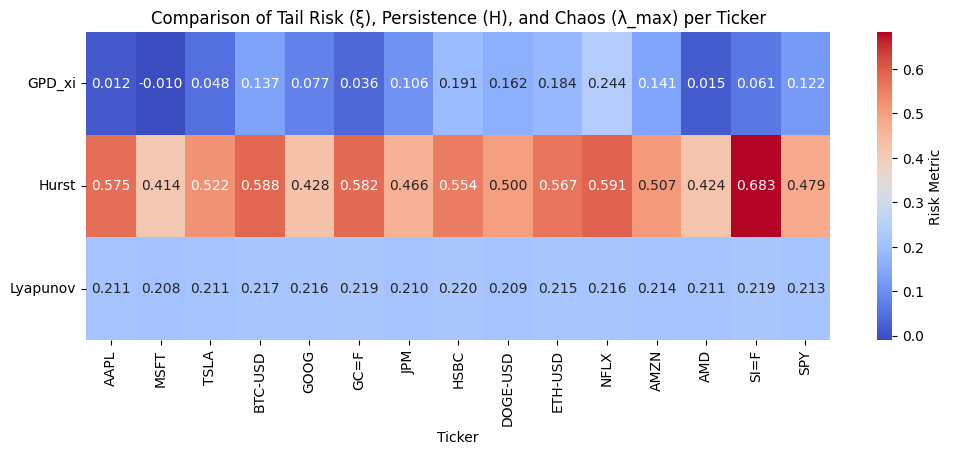

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Use your existing summary DataFrame
data = summary.copy()
data.set_index("Ticker", inplace=True)

# -----------------------------
# Prepare data for heatmap
# -----------------------------
heatmap_data = data[["GPD_xi", "Hurst", "Lyapunov"]].T  # transpose for better plotting

# -----------------------------
# Plot heatmap
# -----------------------------
plt.figure(figsize=(12, 4))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="coolwarm", cbar_kws={'label': 'Risk Metric'})
plt.title("Comparison of Tail Risk (ξ), Persistence (H), and Chaos (λ_max) per Ticker")
plt.yticks(rotation=0)
plt.show()


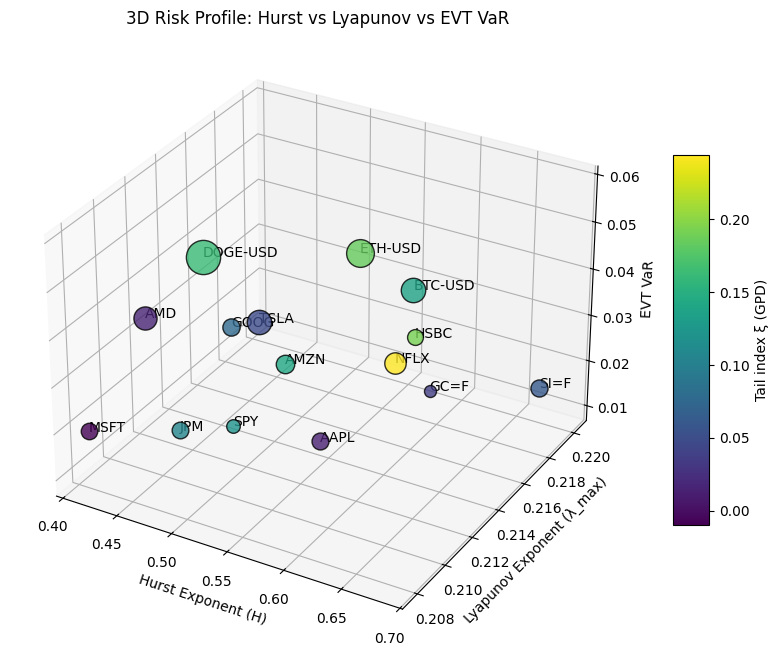

In [22]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm

# Filter out rows where EVT VaR is NaN
plot_data = summary.dropna(subset=['EVT_VaR', 'Hurst', 'Lyapunov'])

fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111, projection='3d')

# Normalize ξ for color mapping
xi_vals = plot_data['GPD_xi'].values
norm_xi = (xi_vals - np.nanmin(xi_vals)) / (np.nanmax(xi_vals) - np.nanmin(xi_vals))
colors = cm.viridis(norm_xi)

# Marker size proportional to Gaussian VaR
sizes = plot_data['Gaussian_VaR'].values * 5000  # scale factor for visibility

for i, row in plot_data.iterrows():
    ax.scatter(row['Hurst'], row['Lyapunov'], row['EVT_VaR'],
               color=colors[i], s=sizes[i], edgecolor='k', alpha=0.8)
    ax.text(row['Hurst'], row['Lyapunov'], row['EVT_VaR'], row['Ticker'], size=10, zorder=1)

ax.set_xlabel('Hurst Exponent (H)')
ax.set_ylabel('Lyapunov Exponent (λ_max)')
ax.set_zlabel('EVT VaR')
ax.set_title('3D Risk Profile: Hurst vs Lyapunov vs EVT VaR')

# Corrected colorbar
mappable = cm.ScalarMappable(cmap='viridis')
mappable.set_array(xi_vals)
cbar = fig.colorbar(mappable, ax=ax, shrink=0.6, aspect=10)  # <- associate with fig
cbar.set_label('Tail index ξ (GPD)')

plt.show()
